<a href="https://colab.research.google.com/github/ManuelSena25/Dental-Lesion-Detection/blob/main/05_Deep_Learning_Organized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dental Lesion Classification — Deep Learning
**Custom CNN · MobileNetV2 · Fine-Tuning · Data Augmentation**

Validation only. The test set is reserved for final evaluation.

In [ ]:

from google.colab import drive

#Connect Google Drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from pathlib import Path
import tensorflow as tf

#Set the dataset path in Google Drive
DATA_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection/dataset/lesion_crops")

#Check dataset and GPU availability
print("Dataset found:", DATA_DIR.exists())
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

#Check the number of images in each split
for split in ["train", "validation", "test"]:
    folder = DATA_DIR / split
    images = [p for label in ["3", "4", "5"] for p in (folder / label).glob("*.jpg")] if folder.exists() else []
    print(f"{split}: {len(images)} images")


Dataset found: True
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
train: 4573 images
validation: 1058 images
test: 1000 images


In [ ]:

import shutil
from pathlib import Path

#Copy the dataset to Colab local storage
LOCAL_DIR = Path("/content/lesion_crops")

for split in ["train", "validation", "test"]:
    for label in ["3", "4", "5"]:
        source = DATA_DIR / split / label
        destination = LOCAL_DIR / split / label

        destination.mkdir(parents=True, exist_ok=True)

        for image in source.glob("*.jpg"):
            shutil.copy2(image, destination / image.name)

#Check copied images
for split in ["train", "validation", "test"]:
    total = sum(
        len(list((LOCAL_DIR / split / label).glob("*.jpg")))
        for label in ["3", "4", "5"]
    )
    print(f"{split}: {total} images")


train: 4573 images
validation: 1058 images
test: 1000 images


In [ ]:

import tensorflow as tf

#Set image parameters
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

#Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

#Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DIR / "validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

#Display class names
print("Classes:", train_ds.class_names)

#Optimize dataset loading
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)


Found 4573 files belonging to 3 classes.
Found 1058 files belonging to 3 classes.
Classes: ['3', '4', '5']


## 3. Custom CNN

In [ ]:

from tensorflow.keras import layers, models

#Build the CNN architecture
model_cnn = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(3, activation="softmax")
])

#Compile the model
model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

#Set model output directory
MODELS_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection/models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

#Define training callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        MODELS_DIR / "custom_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

#Train the custom CNN
history_cnn = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 29s 140ms/step - accuracy: 0.6291 - loss: 0.9059 - val_accuracy: 0.6295 - val_loss: 0.8888
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6350 - loss: 0.8816 - val_accuracy: 0.6295 - val_loss: 0.8885
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.6350 - loss: 0.8735 - val_accuracy: 0.6295 - val_loss: 0.8723
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6350 - loss: 0.8558 - val_accuracy: 0.6295 - val_loss: 0.8452
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.6350 - loss: 0.8372 - val_accuracy: 0.6295 - val_loss: 0.8555
Epoch 6/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6350 - loss: 0.8195 - val_accuracy: 0.6295 - val_loss: 0.8107
Epoch 7/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6350 - loss: 0.8237 - val_accuracy: 0.6295 - val_loss: 0.8242
Epoch 8/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6350 - loss: 0.8201 - val_ac

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, f1_score

#Get validation labels and predictions
y_true = np.concatenate([labels.numpy() for images, labels in val_ds])

y_prob = model_cnn.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

#Calculate model metrics
cnn_accuracy = accuracy_score(y_true, y_pred)
cnn_f1 = f1_score(y_true, y_pred, average="macro")

print("Custom CNN - Validation Results")
print(f"Accuracy: {cnn_accuracy:.4f}")
print(f"Macro F1: {cnn_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["PAI 3", "PAI 4", "PAI 5"]
))


34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step
Custom CNN - Validation Results
Accuracy: 0.6654
Macro F1: 0.3691

Classification Report:
              precision    recall  f1-score   support

       PAI 3       0.70      0.97      0.81       666
       PAI 4       0.45      0.22      0.30       274
       PAI 5       0.00      0.00      0.00       118

    accuracy                           0.67      1058
   macro avg       0.38      0.40      0.37      1058
weighted avg       0.56      0.67      0.59      1058



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


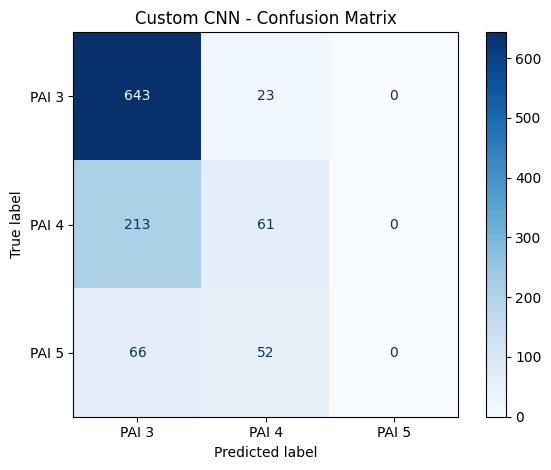

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

#Create confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("Custom CNN - Confusion Matrix")
plt.tight_layout()
plt.show()


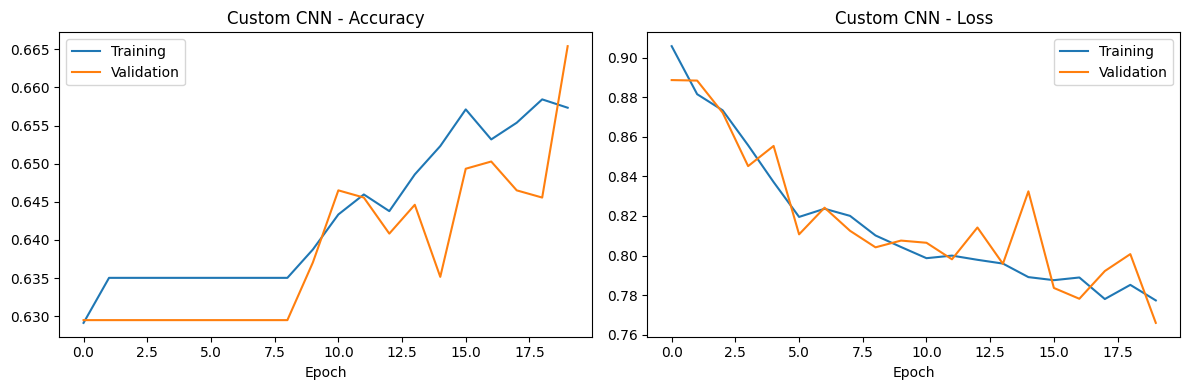

In [ ]:

#Plot accuracy and loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_cnn.history["accuracy"], label="Training")
axes[0].plot(history_cnn.history["val_accuracy"], label="Validation")
axes[0].set_title("Custom CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_cnn.history["loss"], label="Training")
axes[1].plot(history_cnn.history["val_loss"], label="Validation")
axes[1].set_title("Custom CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. MobileNetV2 — Transfer Learning

In [ ]:

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

#Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

#Freeze pretrained layers
base_model.trainable = False

#Build classification model
inputs = layers.Input(shape=(128, 128, 3))

#Normalize images for MobileNetV2
x = layers.Rescaling(1./127.5, offset=-1)(inputs)

#Extract visual features
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

#Classify PAI severity
outputs = layers.Dense(3, activation="softmax")(x)

model_mobilenet = Model(inputs, outputs)

#Compile model
model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_mobilenet.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

from sklearn.utils.class_weight import compute_class_weight

#Calculate class weights
train_labels = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_labels
)

class_weights = dict(enumerate(weights))
print("Class weights:", class_weights)

#Save the best model
mobilenet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        MODELS_DIR / "mobilenet_v2.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

#Train MobileNetV2
history_mobilenet = model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=mobilenet_callbacks
)


Class weights: {0: np.float64(0.5249081726354453), 1: np.float64(1.2777312098351494), 2: np.float64(3.2023809523809526)}
Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 56s 241ms/step - accuracy: 0.6661 - loss: 0.7700 - val_accuracy: 0.7505 - val_loss: 0.5441
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7376 - loss: 0.6040 - val_accuracy: 0.7297 - val_loss: 0.6248
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7516 - loss: 0.5721 - val_accuracy: 0.7495 - val_loss: 0.5765
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7647 - loss: 0.5330 - val_accuracy: 0.7552 - val_loss: 0.5503
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7606 - loss: 0.5350 - val_accuracy: 0.7524 - val_loss: 0.5599


34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 98ms/step
MobileNetV2 - Validation Results
Accuracy: 0.7505
Macro F1: 0.7154
              precision    recall  f1-score   support

       PAI 3       0.89      0.80      0.84       666
       PAI 4       0.52      0.64      0.57       274
       PAI 5       0.72      0.75      0.74       118

    accuracy                           0.75      1058
   macro avg       0.71      0.73      0.72      1058
weighted avg       0.77      0.75      0.76      1058



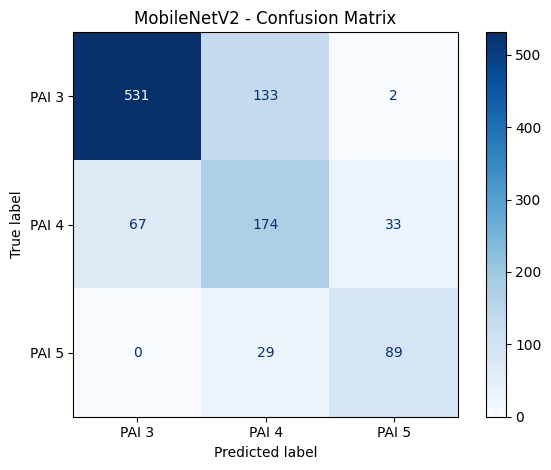

In [ ]:

from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

#Get validation predictions
y_true = np.concatenate([labels.numpy() for images, labels in val_ds])
y_prob = model_mobilenet.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

#Calculate validation metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print("MobileNetV2 - Validation Results")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

#Display classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=["PAI 3", "PAI 4", "PAI 5"]
))

#Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout()
plt.show()


## 5. MobileNetV2 — Fine-Tuning

In [ ]:

#Unfreeze the last 30 layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

#Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

#Use a smaller learning rate
model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#Save the best fine-tuned model
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        MODELS_DIR / "mobilenet_v2_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

#Fine-tune MobileNetV2
history_finetune = model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)


Epoch 1/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 30s 121ms/step - accuracy: 0.7431 - loss: 0.6021 - val_accuracy: 0.7108 - val_loss: 0.6468
Epoch 2/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.7662 - loss: 0.5410 - val_accuracy: 0.7457 - val_loss: 0.5619
Epoch 3/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.7684 - loss: 0.5140 - val_accuracy: 0.7628 - val_loss: 0.5446
Epoch 4/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.7791 - loss: 0.4951 - val_accuracy: 0.7628 - val_loss: 0.5490
Epoch 5/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7809 - loss: 0.4765 - val_accuracy: 0.7722 - val_loss: 0.4979
Epoch 6/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7866 - loss: 0.4612 - val_accuracy: 0.7703 - val_loss: 0.5339
Epoch 7/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7916 - loss: 0.4529 - val_accuracy: 0.7694 - val_loss: 0.5220
Epoch 8/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7953 - loss: 0.4491 - val_ac

34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step
MobileNetV2 Fine-Tuning - Validation Results
Accuracy: 0.7769
Macro F1: 0.7329
              precision    recall  f1-score   support

       PAI 3       0.88      0.85      0.86       666
       PAI 4       0.57      0.61      0.59       274
       PAI 5       0.74      0.75      0.74       118

    accuracy                           0.78      1058
   macro avg       0.73      0.74      0.73      1058
weighted avg       0.78      0.78      0.78      1058



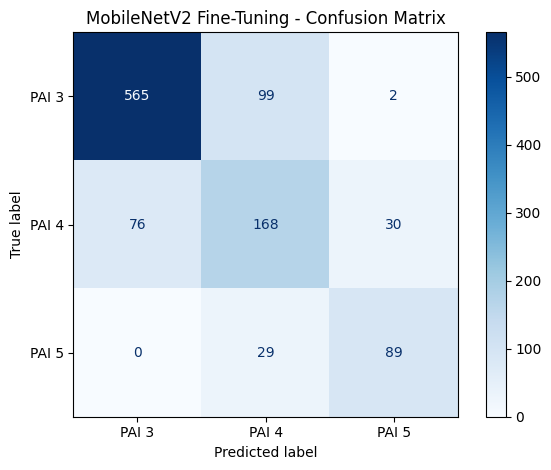

In [ ]:

from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

#Load the best fine-tuned model
model_finetuned = tf.keras.models.load_model(
    MODELS_DIR / "mobilenet_v2_finetuned.keras"
)

#Get validation predictions
y_true = np.concatenate([labels.numpy() for images, labels in val_ds])
y_prob = model_finetuned.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

#Calculate validation metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print("MobileNetV2 Fine-Tuning - Validation Results")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

#Display classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=["PAI 3", "PAI 4", "PAI 5"]
))

#Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("MobileNetV2 Fine-Tuning - Confusion Matrix")
plt.tight_layout()
plt.show()


## 6. MobileNetV2 — Data Augmentation

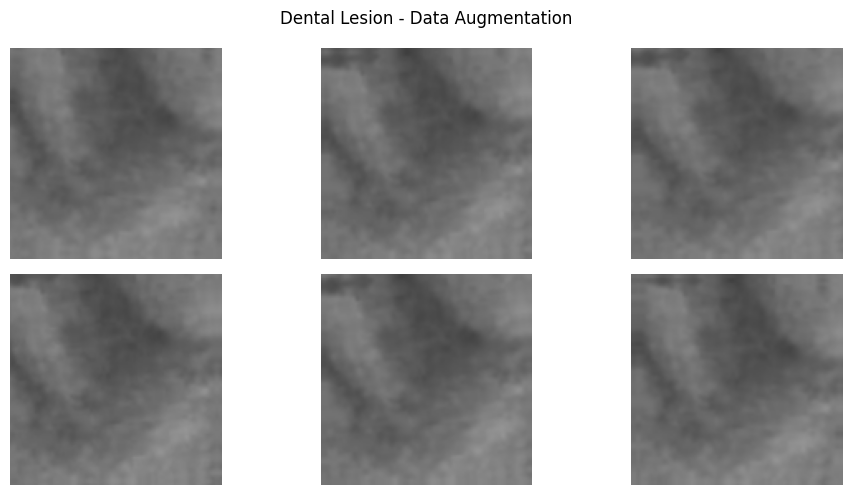

In [ ]:

from tensorflow.keras import layers

#Create data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.03, 0.03),
    layers.RandomContrast(0.1)
])

#Display augmented images
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 5))

for i in range(6):
    augmented = data_augmentation(images[:1], training=True)

    plt.subplot(2, 3, i + 1)
    plt.imshow(augmented[0].numpy().astype("uint8"))
    plt.axis("off")

plt.suptitle("Dental Lesion - Data Augmentation")
plt.tight_layout()
plt.show()


In [ ]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import Model

#Load a fresh pretrained model
base_aug = MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

#Freeze pretrained layers
base_aug.trainable = False

#Build the augmented model
inputs = layers.Input(shape=(128, 128, 3))

#Apply augmentation during training
x = data_augmentation(inputs)

#Normalize for MobileNetV2
x = layers.Rescaling(1./127.5, offset=-1)(x)

#Extract image features
x = base_aug(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

#Predict PAI severity
outputs = layers.Dense(3, activation="softmax")(x)

model_aug = Model(inputs, outputs)

#Compile model
model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_aug.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

#Create callbacks
aug_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        MODELS_DIR / "mobilenet_v2_augmented.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

#Train augmented MobileNetV2
history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=aug_callbacks
)


Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 17s 63ms/step - accuracy: 0.6733 - loss: 0.7379 - val_accuracy: 0.6824 - val_loss: 0.7540
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.7328 - loss: 0.6263 - val_accuracy: 0.7146 - val_loss: 0.6959
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.7505 - loss: 0.6016 - val_accuracy: 0.6049 - val_loss: 0.9592
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.7509 - loss: 0.5711 - val_accuracy: 0.6654 - val_loss: 0.8026
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7606 - loss: 0.5618 - val_accuracy: 0.6408 - val_loss: 0.8883
Epoch 6/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.7616 - loss: 0.5524 - val_accuracy: 0.6767 - val_loss: 0.7943


34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step
MobileNetV2 + Augmentation
Accuracy: 0.7146
Macro F1: 0.6895
              precision    recall  f1-score   support

       PAI 3       0.93      0.71      0.81       666
       PAI 4       0.48      0.65      0.55       274
       PAI 5       0.59      0.90      0.71       118

    accuracy                           0.71      1058
   macro avg       0.67      0.75      0.69      1058
weighted avg       0.78      0.71      0.73      1058



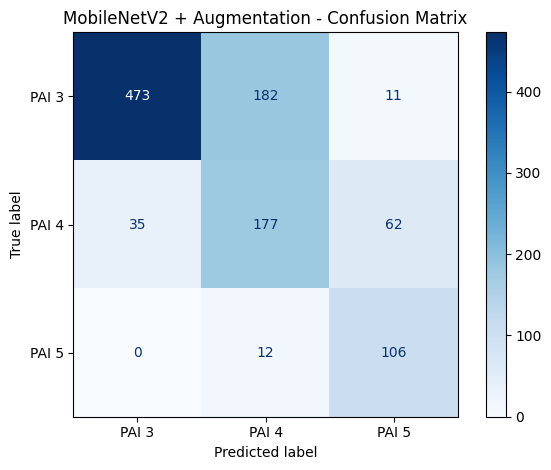

In [ ]:

#Load the best augmented model
model_aug_best = tf.keras.models.load_model(
    MODELS_DIR / "mobilenet_v2_augmented.keras"
)

#Get validation predictions
y_true = np.concatenate([labels.numpy() for images, labels in val_ds])
y_prob = model_aug_best.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

#Calculate validation metrics
aug_accuracy = accuracy_score(y_true, y_pred)
aug_f1 = f1_score(y_true, y_pred, average="macro")

print("MobileNetV2 + Augmentation")
print(f"Accuracy: {aug_accuracy:.4f}")
print(f"Macro F1: {aug_f1:.4f}")

#Display classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=["PAI 3", "PAI 4", "PAI 5"]
))

#Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("MobileNetV2 + Augmentation - Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, Model

#Load pretrained ResNet50
base_resnet = ResNet50(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

#Freeze pretrained layers
base_resnet.trainable = False

#Build classification model
inputs = layers.Input(shape=(128, 128, 3))

#Apply ResNet50 preprocessing
x = layers.Lambda(
    tf.keras.applications.resnet50.preprocess_input
)(inputs)

#Extract image features
x = base_resnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

#Predict PAI severity
outputs = layers.Dense(3, activation="softmax")(x)

model_resnet = Model(inputs, outputs)

#Compile model
model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_resnet.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:

#Define training callbacks
resnet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        MODELS_DIR / "resnet50.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

#Train ResNet50
history_resnet = model_resnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=resnet_callbacks
)


Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 61s 280ms/step - accuracy: 0.6350 - loss: 0.8697 - val_accuracy: 0.7552 - val_loss: 0.5787
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.7243 - loss: 0.6478 - val_accuracy: 0.7930 - val_loss: 0.5174
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.7525 - loss: 0.5733 - val_accuracy: 0.7977 - val_loss: 0.5085
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.7612 - loss: 0.5557 - val_accuracy: 0.8062 - val_loss: 0.4976
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.7673 - loss: 0.5241 - val_accuracy: 0.8081 - val_loss: 0.4750
Epoch 6/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.7796 - loss: 0.5090 - val_accuracy: 0.7940 - val_loss: 0.5175
Epoch 7/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.7842 - loss: 0.4996 - val_accuracy: 0.7873 - val_loss: 0.5246
Epoch 8/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.7920 - loss: 0.4837 - val_ac

ResNet50 loaded successfully!
34/34 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step

ResNet50 - Validation Results
Accuracy: 0.8081
Macro F1: 0.7511

Classification Report:
              precision    recall  f1-score   support

       PAI 3       0.88      0.90      0.89       666
       PAI 4       0.65      0.62      0.63       274
       PAI 5       0.74      0.71      0.73       118

    accuracy                           0.81      1058
   macro avg       0.76      0.75      0.75      1058
weighted avg       0.81      0.81      0.81      1058



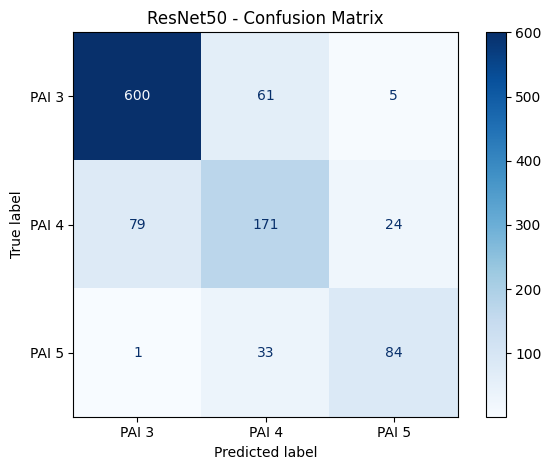

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

#Set model directory
MODELS_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection/models")

#Load the trained ResNet50 model
model_resnet_best = tf.keras.models.load_model(
    MODELS_DIR / "resnet50.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("ResNet50 loaded successfully!")

#Get validation labels
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

#Predict validation images
y_prob = model_resnet_best.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

#Calculate validation metrics
resnet_accuracy = accuracy_score(y_true, y_pred)
resnet_f1 = f1_score(y_true, y_pred, average="macro")

print("\nResNet50 - Validation Results")
print(f"Accuracy: {resnet_accuracy:.4f}")
print(f"Macro F1: {resnet_f1:.4f}")

#Display classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["PAI 3", "PAI 4", "PAI 5"]
))

#Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("ResNet50 - Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path

#Set project directory
PROJECT_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection")

#Search for original images and annotations
jpg_files = list(PROJECT_DIR.rglob("*.jpg"))
xml_files = list(PROJECT_DIR.rglob("*.xml"))

print("JPG files:", len(jpg_files))
print("XML files:", len(xml_files))

#Show example files
print("\nExample JPG files:")
for file in jpg_files[:5]:
    print(file)

print("\nExample XML files:")
for file in xml_files[:5]:
    print(file)


JPG files: 10515
XML files: 0

Example JPG files:
/content/drive/MyDrive/Dental_Lesion_Detection/models/yolo11_detection/labels.jpg
/content/drive/MyDrive/Dental_Lesion_Detection/models/yolo11_detection/train_batch0.jpg
/content/drive/MyDrive/Dental_Lesion_Detection/models/yolo11_detection/train_batch1.jpg
/content/drive/MyDrive/Dental_Lesion_Detection/models/yolo11_detection/train_batch2.jpg
/content/drive/MyDrive/Dental_Lesion_Detection/models/yolo11_detection/train_batch10170.jpg

Example XML files:


In [ ]:

#Install YOLO
%pip install -q ultralytics


In [ ]:

from pathlib import Path
import pandas as pd

#Set project directories
PROJECT_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection")
DATA_DIR = PROJECT_DIR / "dataset"

#Set original dataset paths
IMAGE_DIR = DATA_DIR / "Original JPG Images"
CSV_PATH = DATA_DIR / "dataset_annotations.csv"

#Check uploaded files
print("Image folder exists:", IMAGE_DIR.exists())
print("CSV exists:", CSV_PATH.exists())

#Count original images
images = list(IMAGE_DIR.glob("*.jpg"))
print("Original images:", len(images))

#Load annotations
df_yolo = pd.read_csv(CSV_PATH)

print("Total annotations:", len(df_yolo))
print("\nDataset splits:")
print(df_yolo["split"].value_counts())


Image folder exists: True
CSV exists: True
Original images: 3875
Total annotations: 6631

Dataset splits:
split
train         4573
validation    1058
test          1000
Name: count, dtype: int64


In [ ]:

from pathlib import Path
from PIL import Image
import pandas as pd
import shutil

#Set YOLO dataset directory
YOLO_DIR = Path("/content/yolo_dataset")

#Define class and split mappings
class_map = {3: 0, 4: 1, 5: 2}
split_map = {
    "train": "train",
    "validation": "val",
    "test": "test"
}

#Get image filenames
df_yolo["image_name"] = df_yolo["image"].apply(
    lambda path: str(path).replace("\\", "/").split("/")[-1]
)

#Check image assignments
assert df_yolo["image_name"].nunique() == 3875
assert (df_yolo.groupby("image_name")["split"].nunique() == 1).all()

#Create YOLO folders
for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

#Convert annotations
for image_name, group in df_yolo.groupby("image_name"):
    split = split_map[group["split"].iloc[0]]

    source = IMAGE_DIR / image_name
    destination = YOLO_DIR / "images" / split / image_name

    #Read image dimensions
    with Image.open(source) as image:
        width, height = image.size

    labels = []

    for _, row in group.iterrows():
        xmin = float(row["xmin"])
        ymin = float(row["ymin"])
        xmax = float(row["xmax"])
        ymax = float(row["ymax"])

        #Normalize coordinates
        x = ((xmin + xmax) / 2) / width
        y = ((ymin + ymax) / 2) / height
        w = (xmax - xmin) / width
        h = (ymax - ymin) / height

        class_id = class_map[int(row["class"])]

        labels.append(
            f"{class_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}"
        )

    #Copy original image to Colab
    shutil.copy2(source, destination)

    #Save YOLO label
    label_file = YOLO_DIR / "labels" / split / f"{Path(image_name).stem}.txt"
    label_file.write_text("\n".join(labels) + "\n")

print("YOLO dataset created successfully")


YOLO dataset created successfully


In [ ]:

from pathlib import Path

#Check YOLO dataset
total_images = 0
total_labels = 0
total_boxes = 0

for split in ["train", "val", "test"]:
    image_files = list((YOLO_DIR / "images" / split).glob("*.jpg"))
    label_files = list((YOLO_DIR / "labels" / split).glob("*.txt"))

    boxes = sum(
        len(file.read_text().splitlines())
        for file in label_files
    )

    total_images += len(image_files)
    total_labels += len(label_files)
    total_boxes += boxes

    print(f"\n{split.upper()}")
    print("Images:", len(image_files))
    print("Labels:", len(label_files))
    print("Bounding boxes:", boxes)

print("\nTOTAL")
print("Images:", total_images)
print("Labels:", total_labels)
print("Bounding boxes:", total_boxes)

#Verify expected counts
assert total_images == 3875
assert total_labels == 3875
assert total_boxes == 6631

print("\nDataset verification successful")



TRAIN
Images: 2712
Labels: 2712
Bounding boxes: 4573

VAL
Images: 581
Labels: 581
Bounding boxes: 1058

TEST
Images: 582
Labels: 582
Bounding boxes: 1000

TOTAL
Images: 3875
Labels: 3875
Bounding boxes: 6631

Dataset verification successful


In [ ]:

#Create YOLO dataset configuration
yaml_content = """path: /content/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: PAI_3
  1: PAI_4
  2: PAI_5
"""

#Save configuration
(YOLO_DIR / "data.yaml").write_text(
    yaml_content,
    encoding="utf-8"
)

print("YOLO configuration created!")
print((YOLO_DIR / "data.yaml").read_text())


YOLO configuration created!
path: /content/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: PAI_3
  1: PAI_4
  2: PAI_5



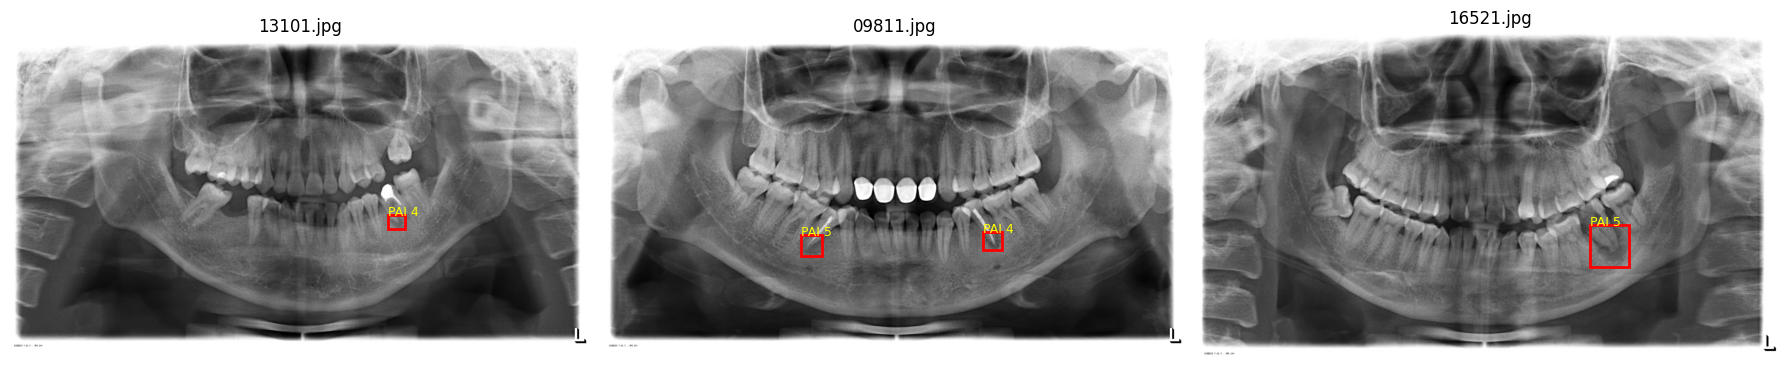

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

#Select random training images
image_files = list((YOLO_DIR / "images" / "train").glob("*.jpg"))
random.seed(42)
sample_images = random.sample(image_files, min(3, len(image_files)))

class_names = ["PAI 3", "PAI 4", "PAI 5"]

fig, axes = plt.subplots(1, len(sample_images), figsize=(18, 6))

if len(sample_images) == 1:
    axes = [axes]

for ax, image_path in zip(axes, sample_images):

    #Load image
    image = Image.open(image_path)
    width, height = image.size

    ax.imshow(image, cmap="gray")

    #Read YOLO labels
    label_path = YOLO_DIR / "labels" / "train" / f"{image_path.stem}.txt"

    for line in label_path.read_text().splitlines():
        class_id, x, y, w, h = map(float, line.split())

        #Convert normalized coordinates to pixels
        xmin = (x - w / 2) * width
        ymin = (y - h / 2) * height

        rect = patches.Rectangle(
            (xmin, ymin),
            w * width,
            h * height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            xmin,
            ymin,
            class_names[int(class_id)],
            color="yellow",
            fontsize=9
        )

    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import torch

#Check GPU availability
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")


CUDA available: True
GPU: Tesla T4


In [ ]:

from ultralytics import YOLO

#Load pretrained YOLO11 model
model_yolo = YOLO("yolo11n.pt")

#Train dental lesion detector
results_yolo = model_yolo.train(
    data=str(YOLO_DIR / "data.yaml"),
    epochs=40,
    imgsz=1024,
    batch=8,
    device=0,
    patience=10,
    project=str(PROJECT_DIR / "models"),
    name="yolo11_detection",
    exist_ok=True
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

In [ ]:

from pathlib import Path

#Set YOLO results directory
YOLO_RESULTS = PROJECT_DIR / "models" / "yolo11_detection"

#List saved results
for file in sorted(YOLO_RESULTS.iterdir()):
    print(file.name)


BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch10170.jpg
train_batch10171.jpg
train_batch10172.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights



results.png


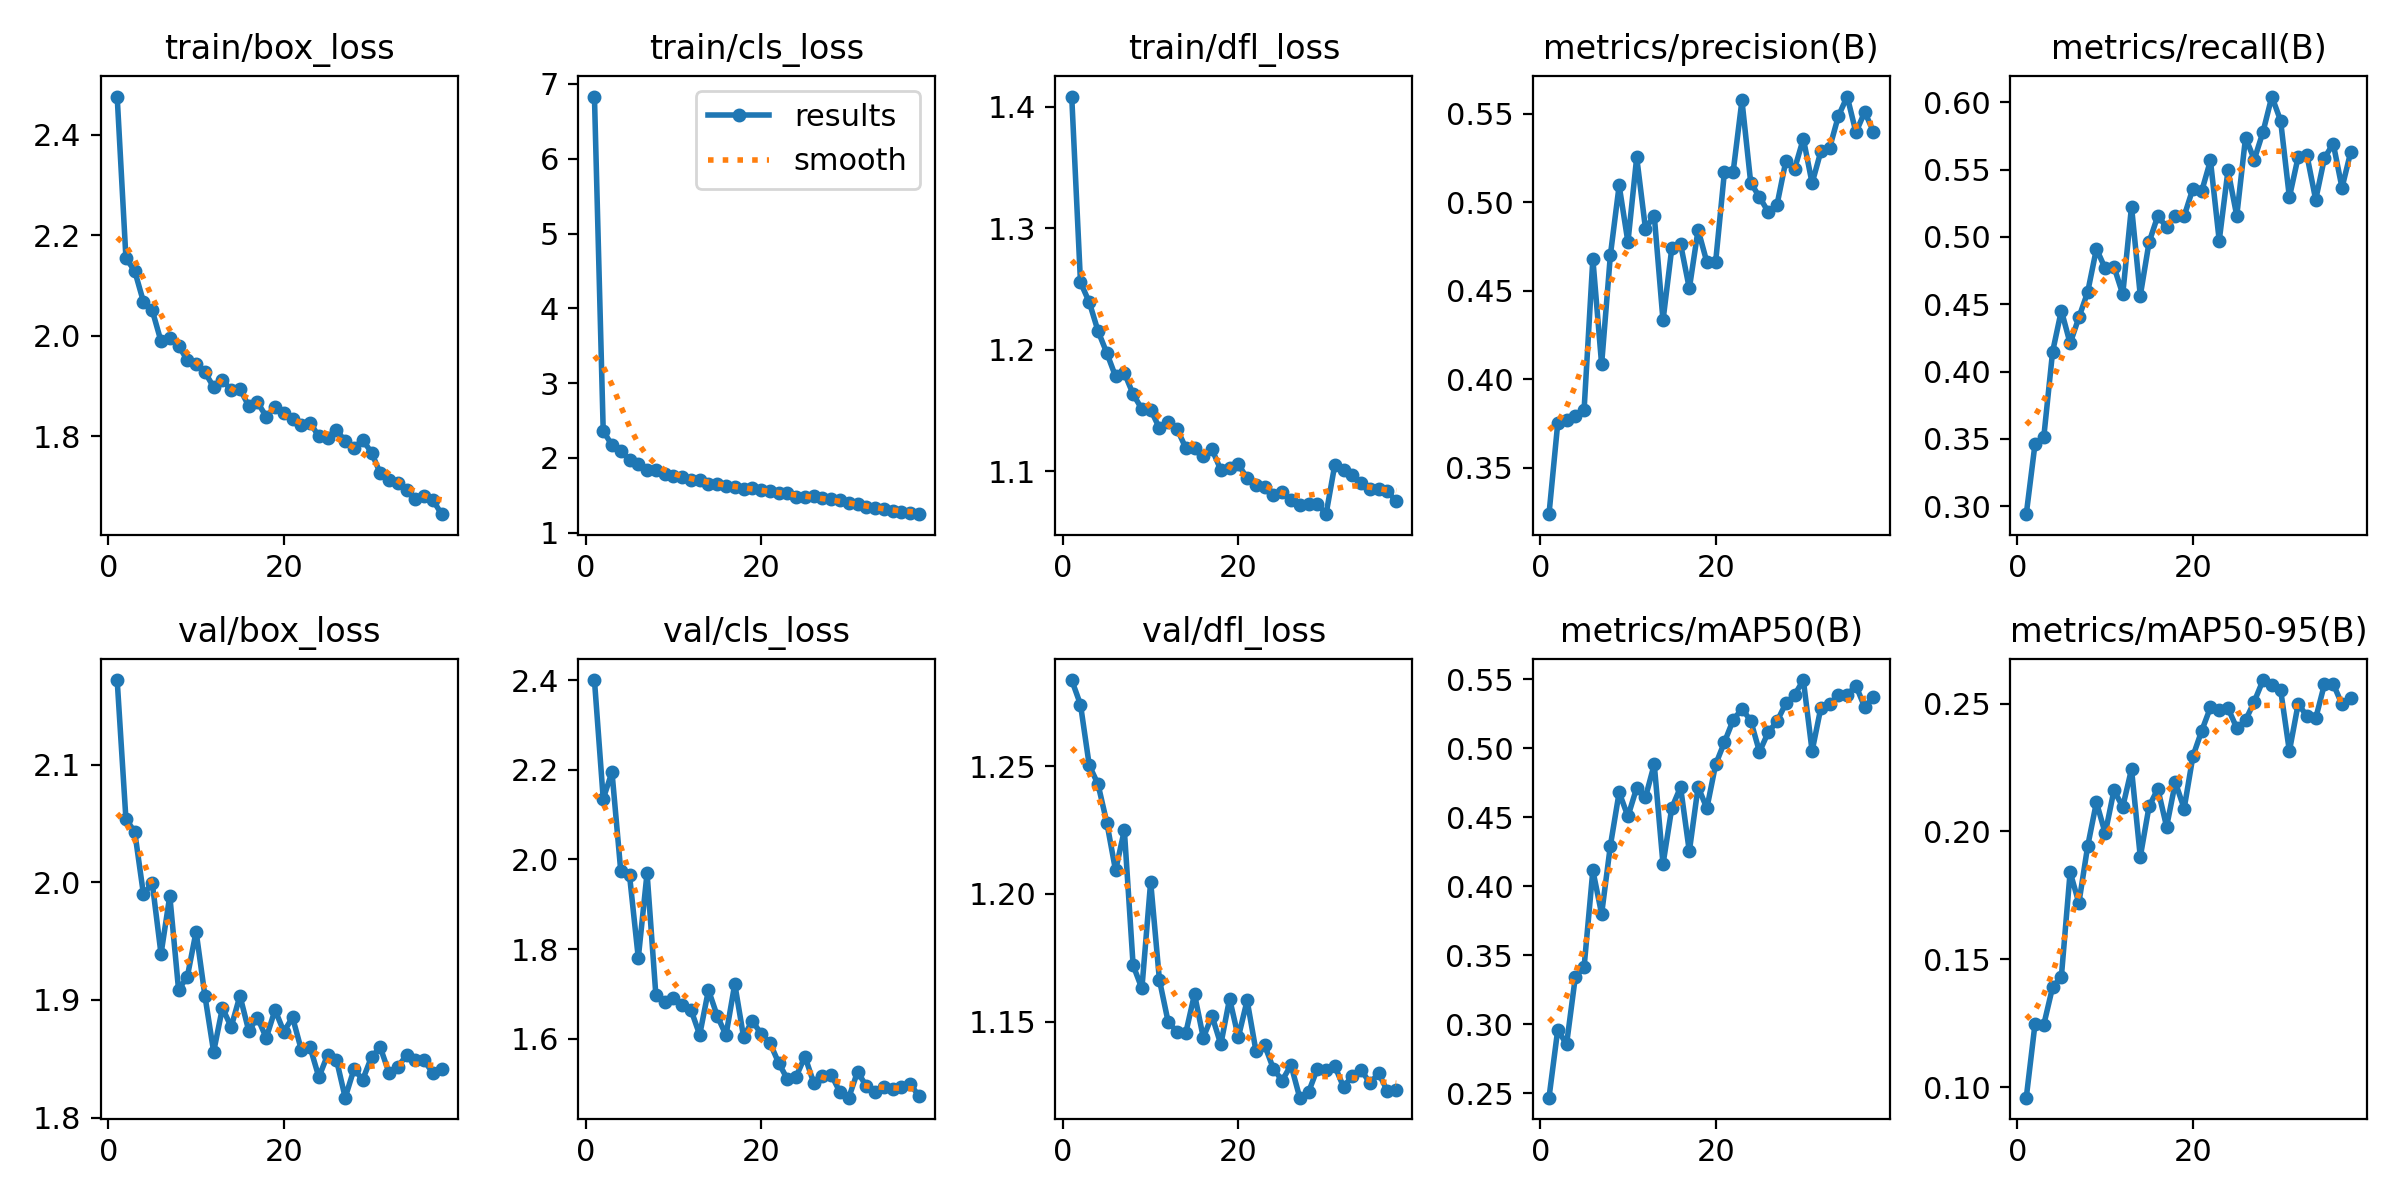


confusion_matrix.png


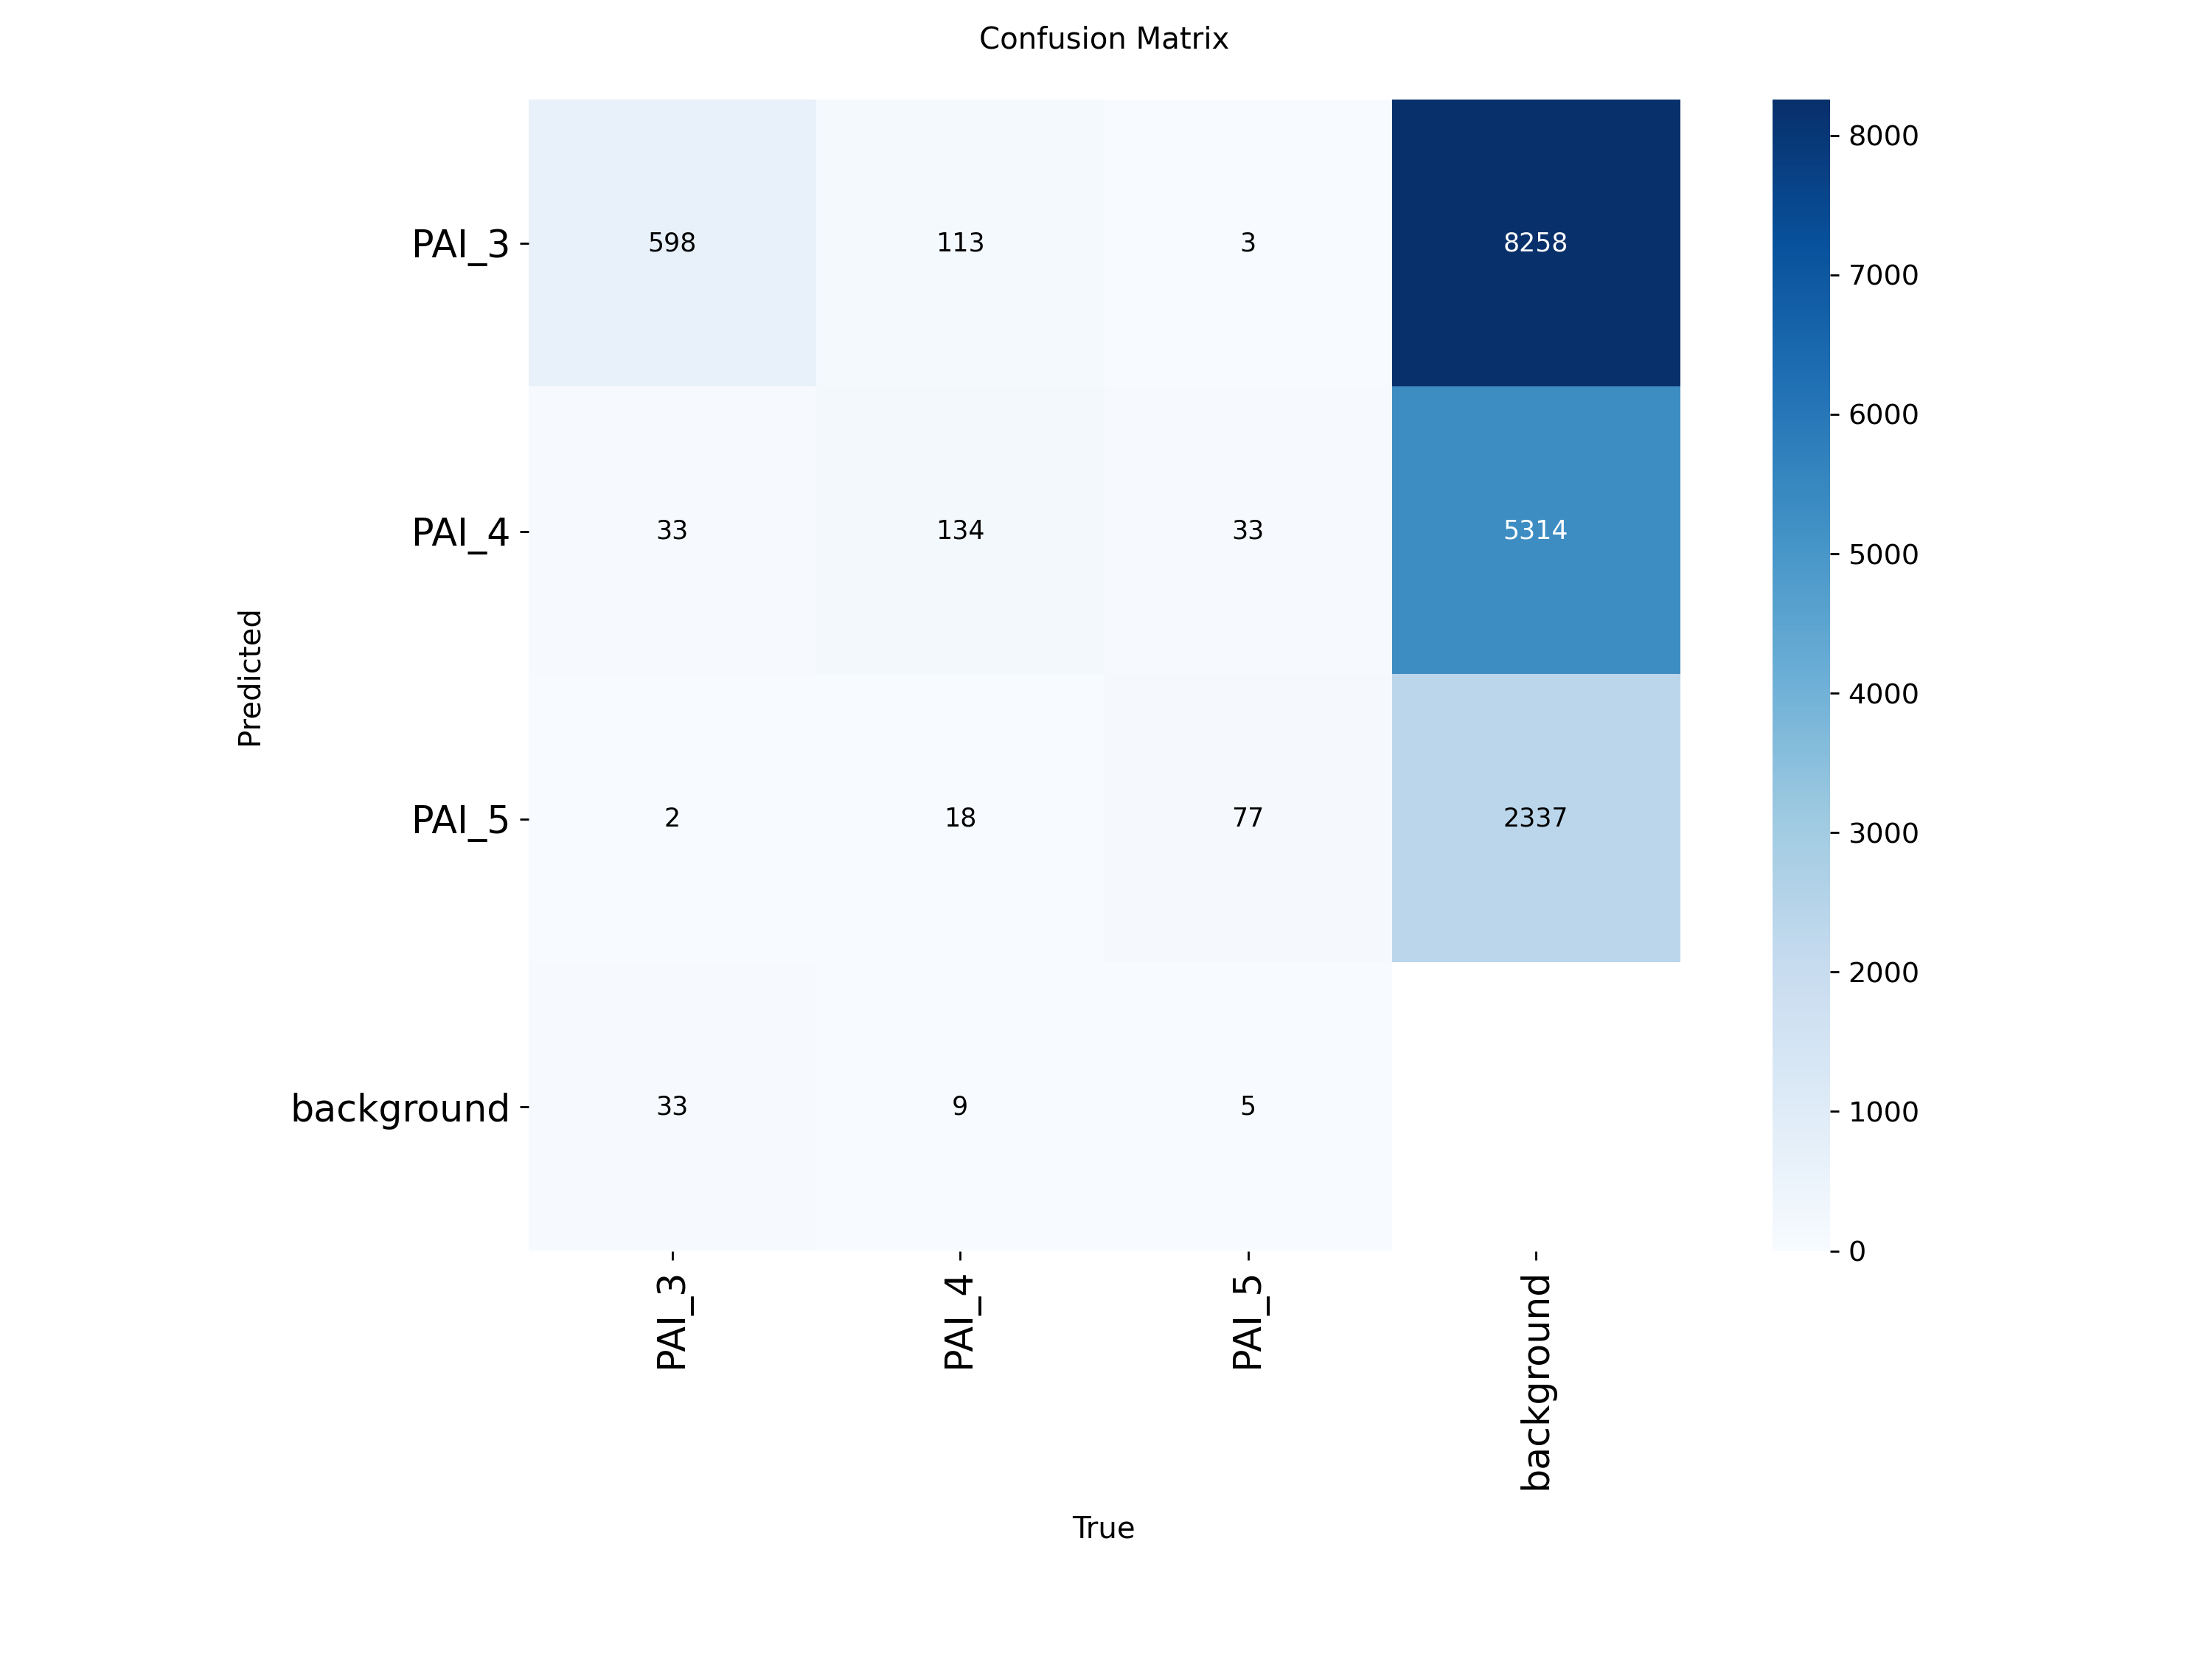

Not found: PR_curve.png
Not found: F1_curve.png


In [ ]:

from IPython.display import display, Image as DisplayImage

#Display YOLO training results
graphs = [
    "results.png",
    "confusion_matrix.png",
    "PR_curve.png",
    "F1_curve.png"
]

for graph in graphs:
    path = YOLO_RESULTS / graph

    if path.exists():
        print(f"\n{graph}")
        display(DisplayImage(filename=str(path)))
    else:
        print(f"Not found: {graph}")



 BoxPR_curve.png


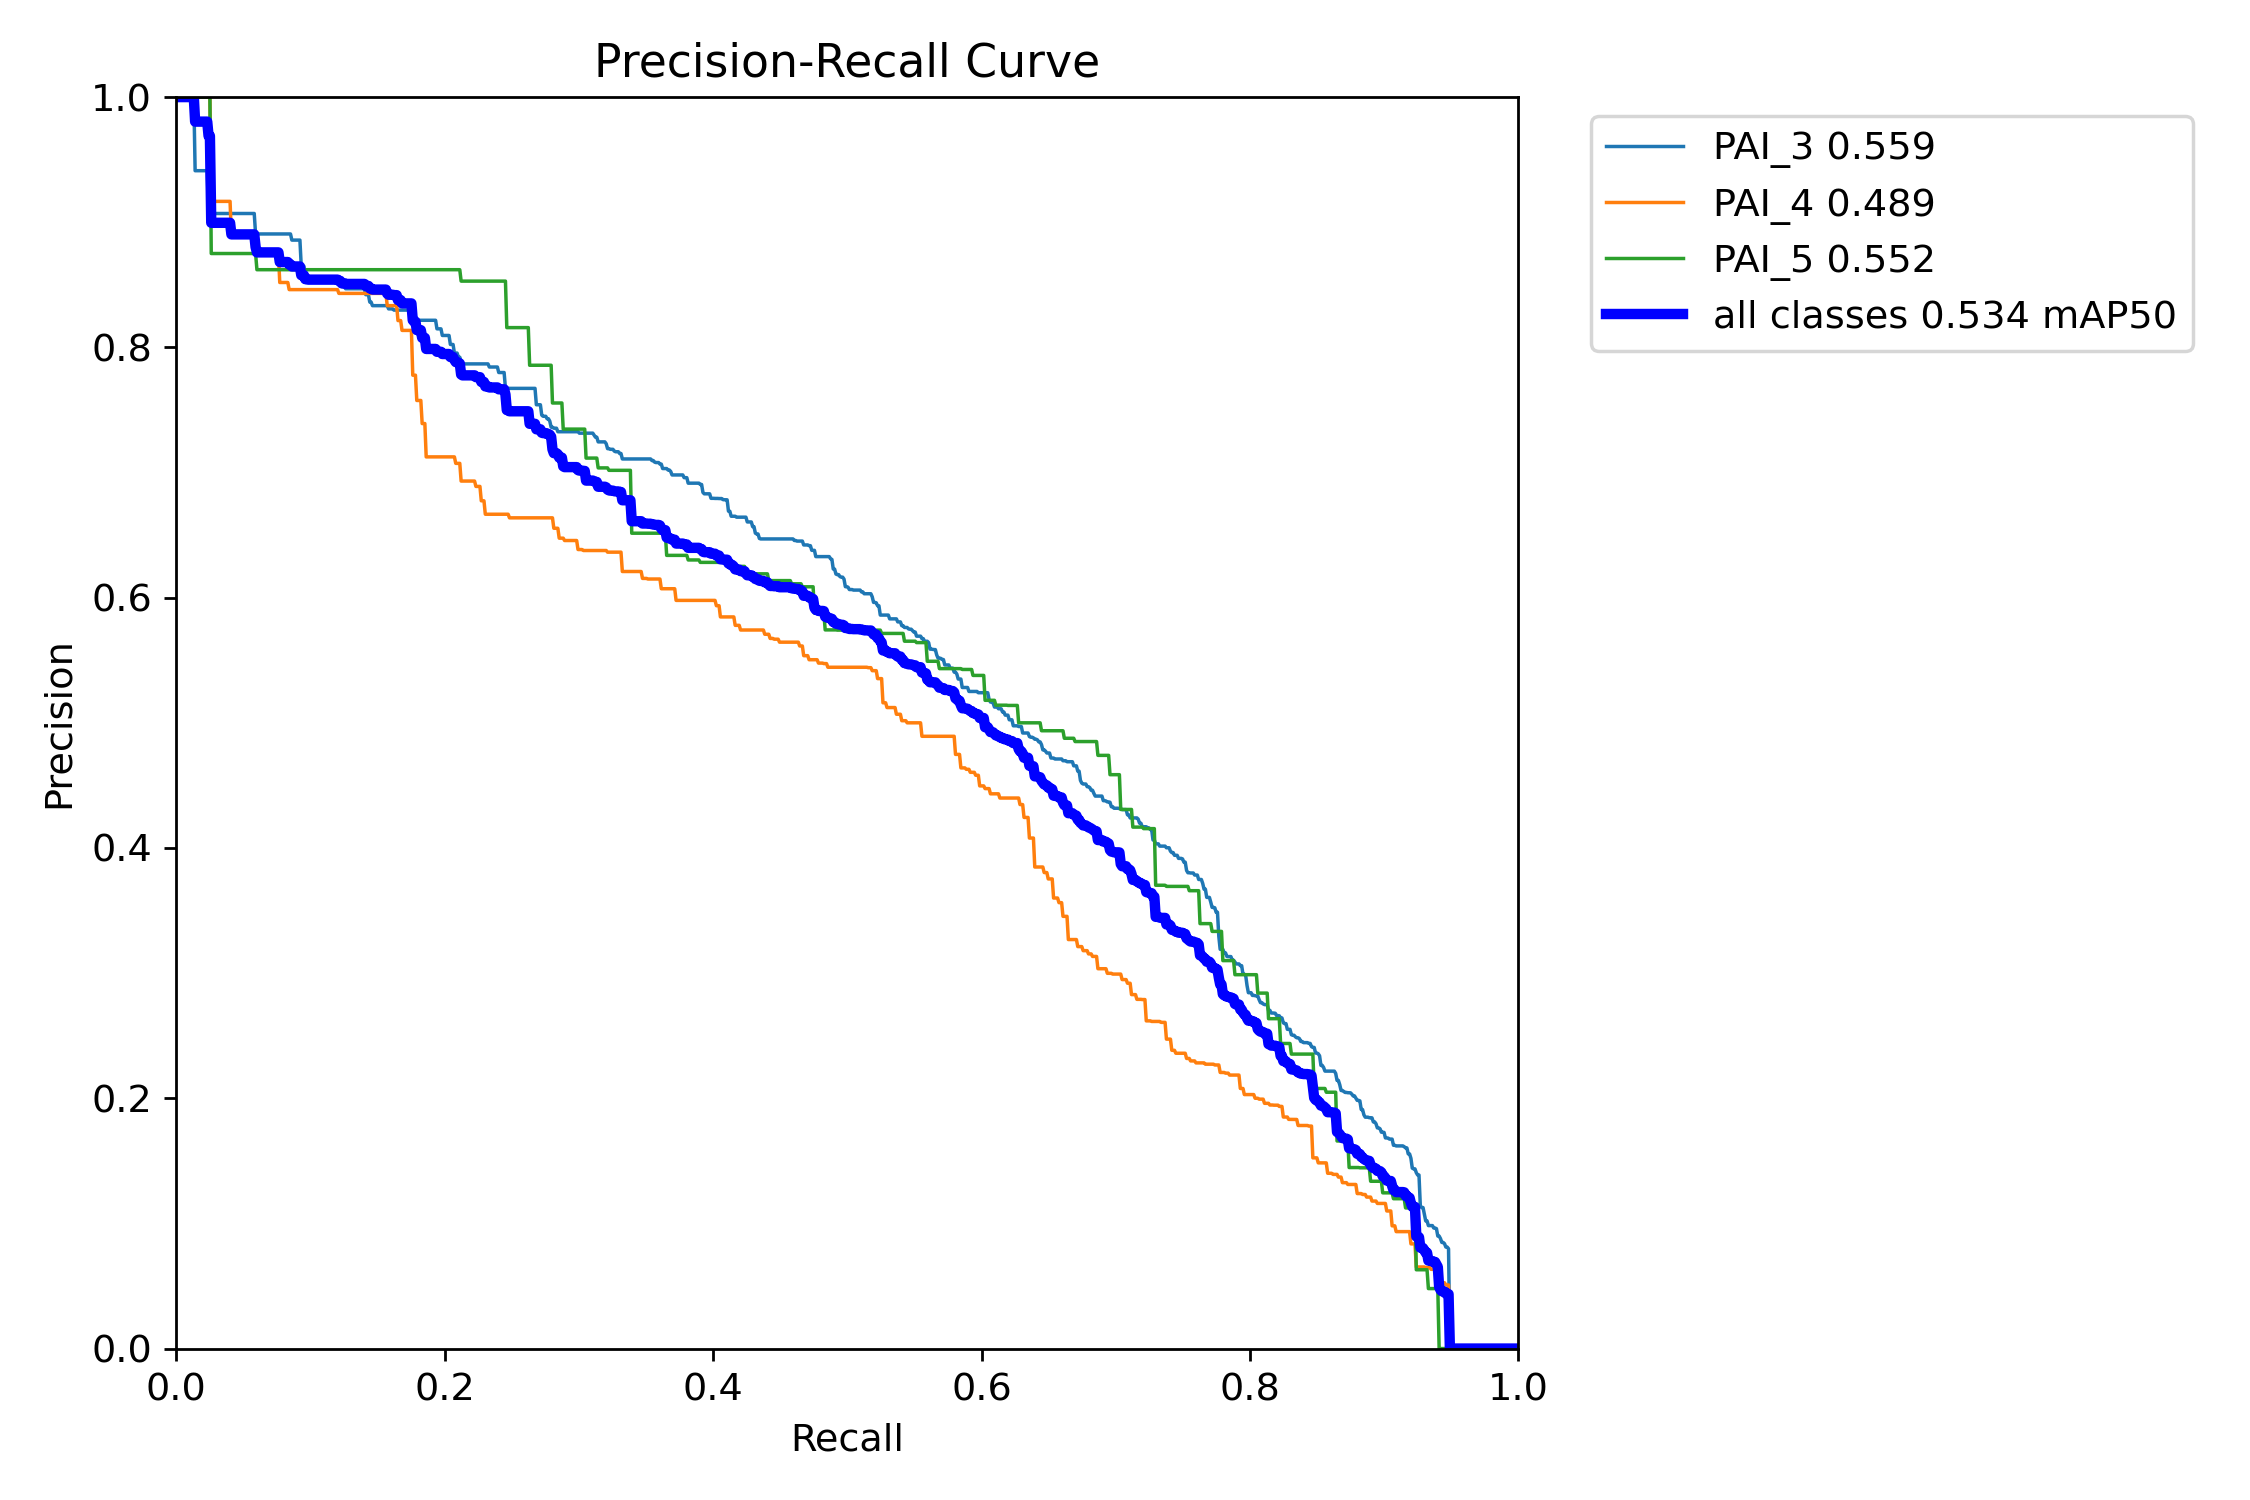


 BoxF1_curve.png


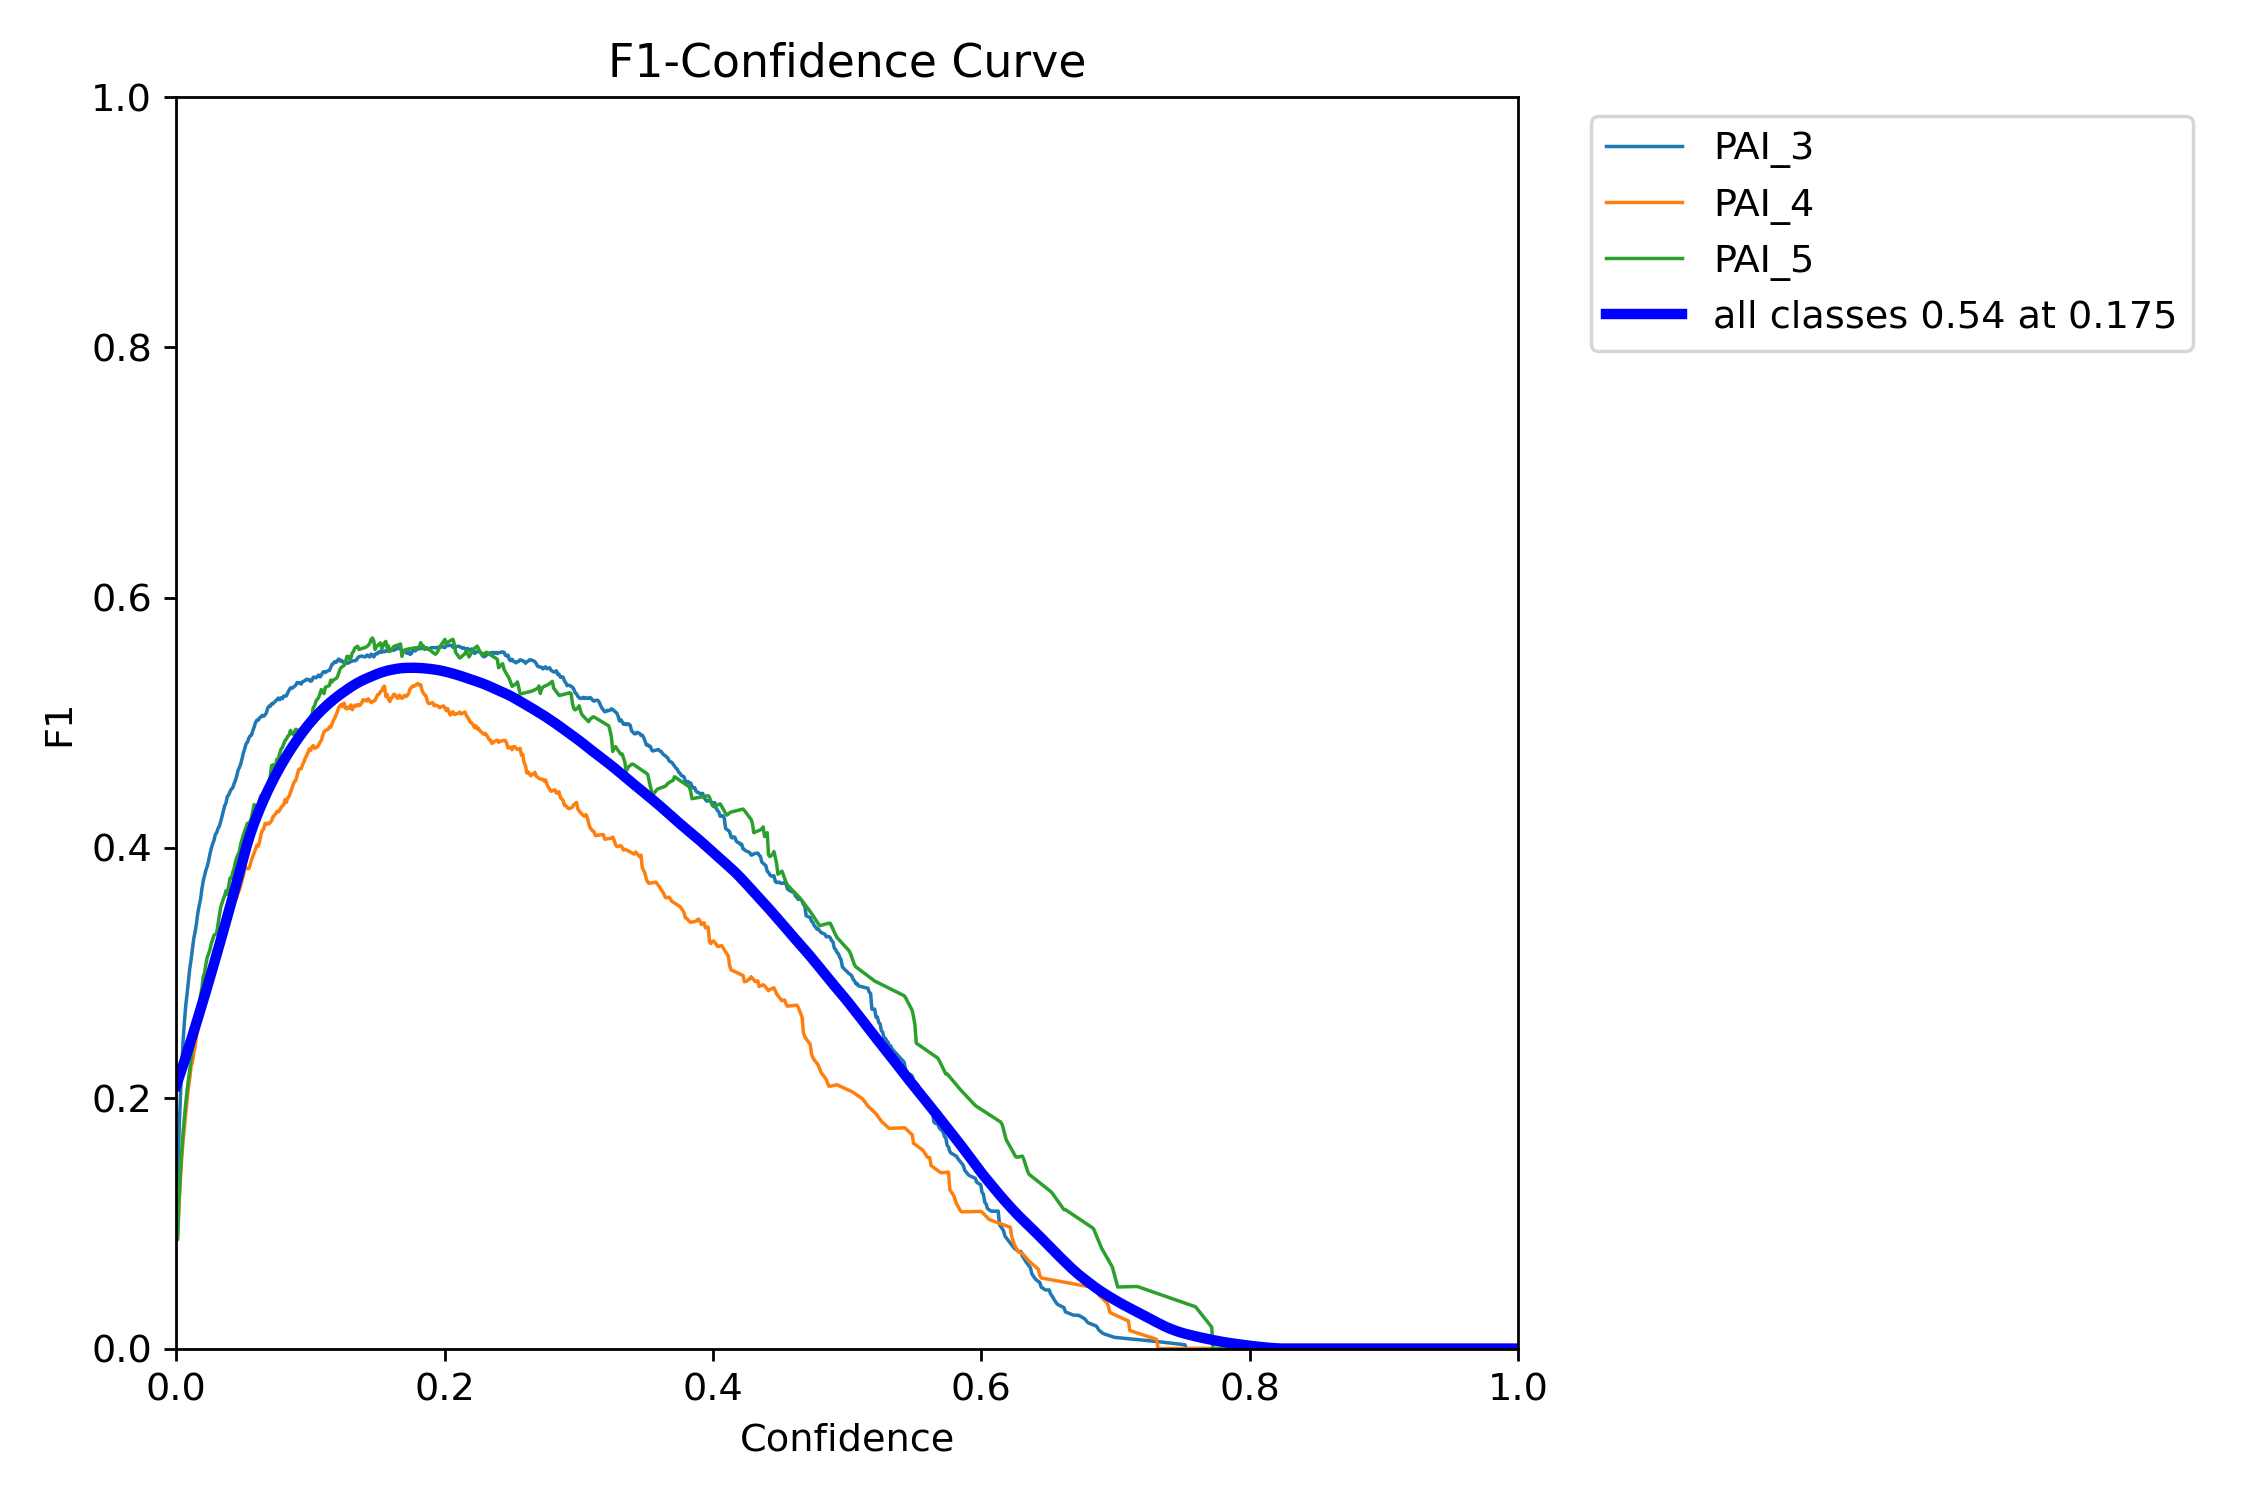


 BoxP_curve.png


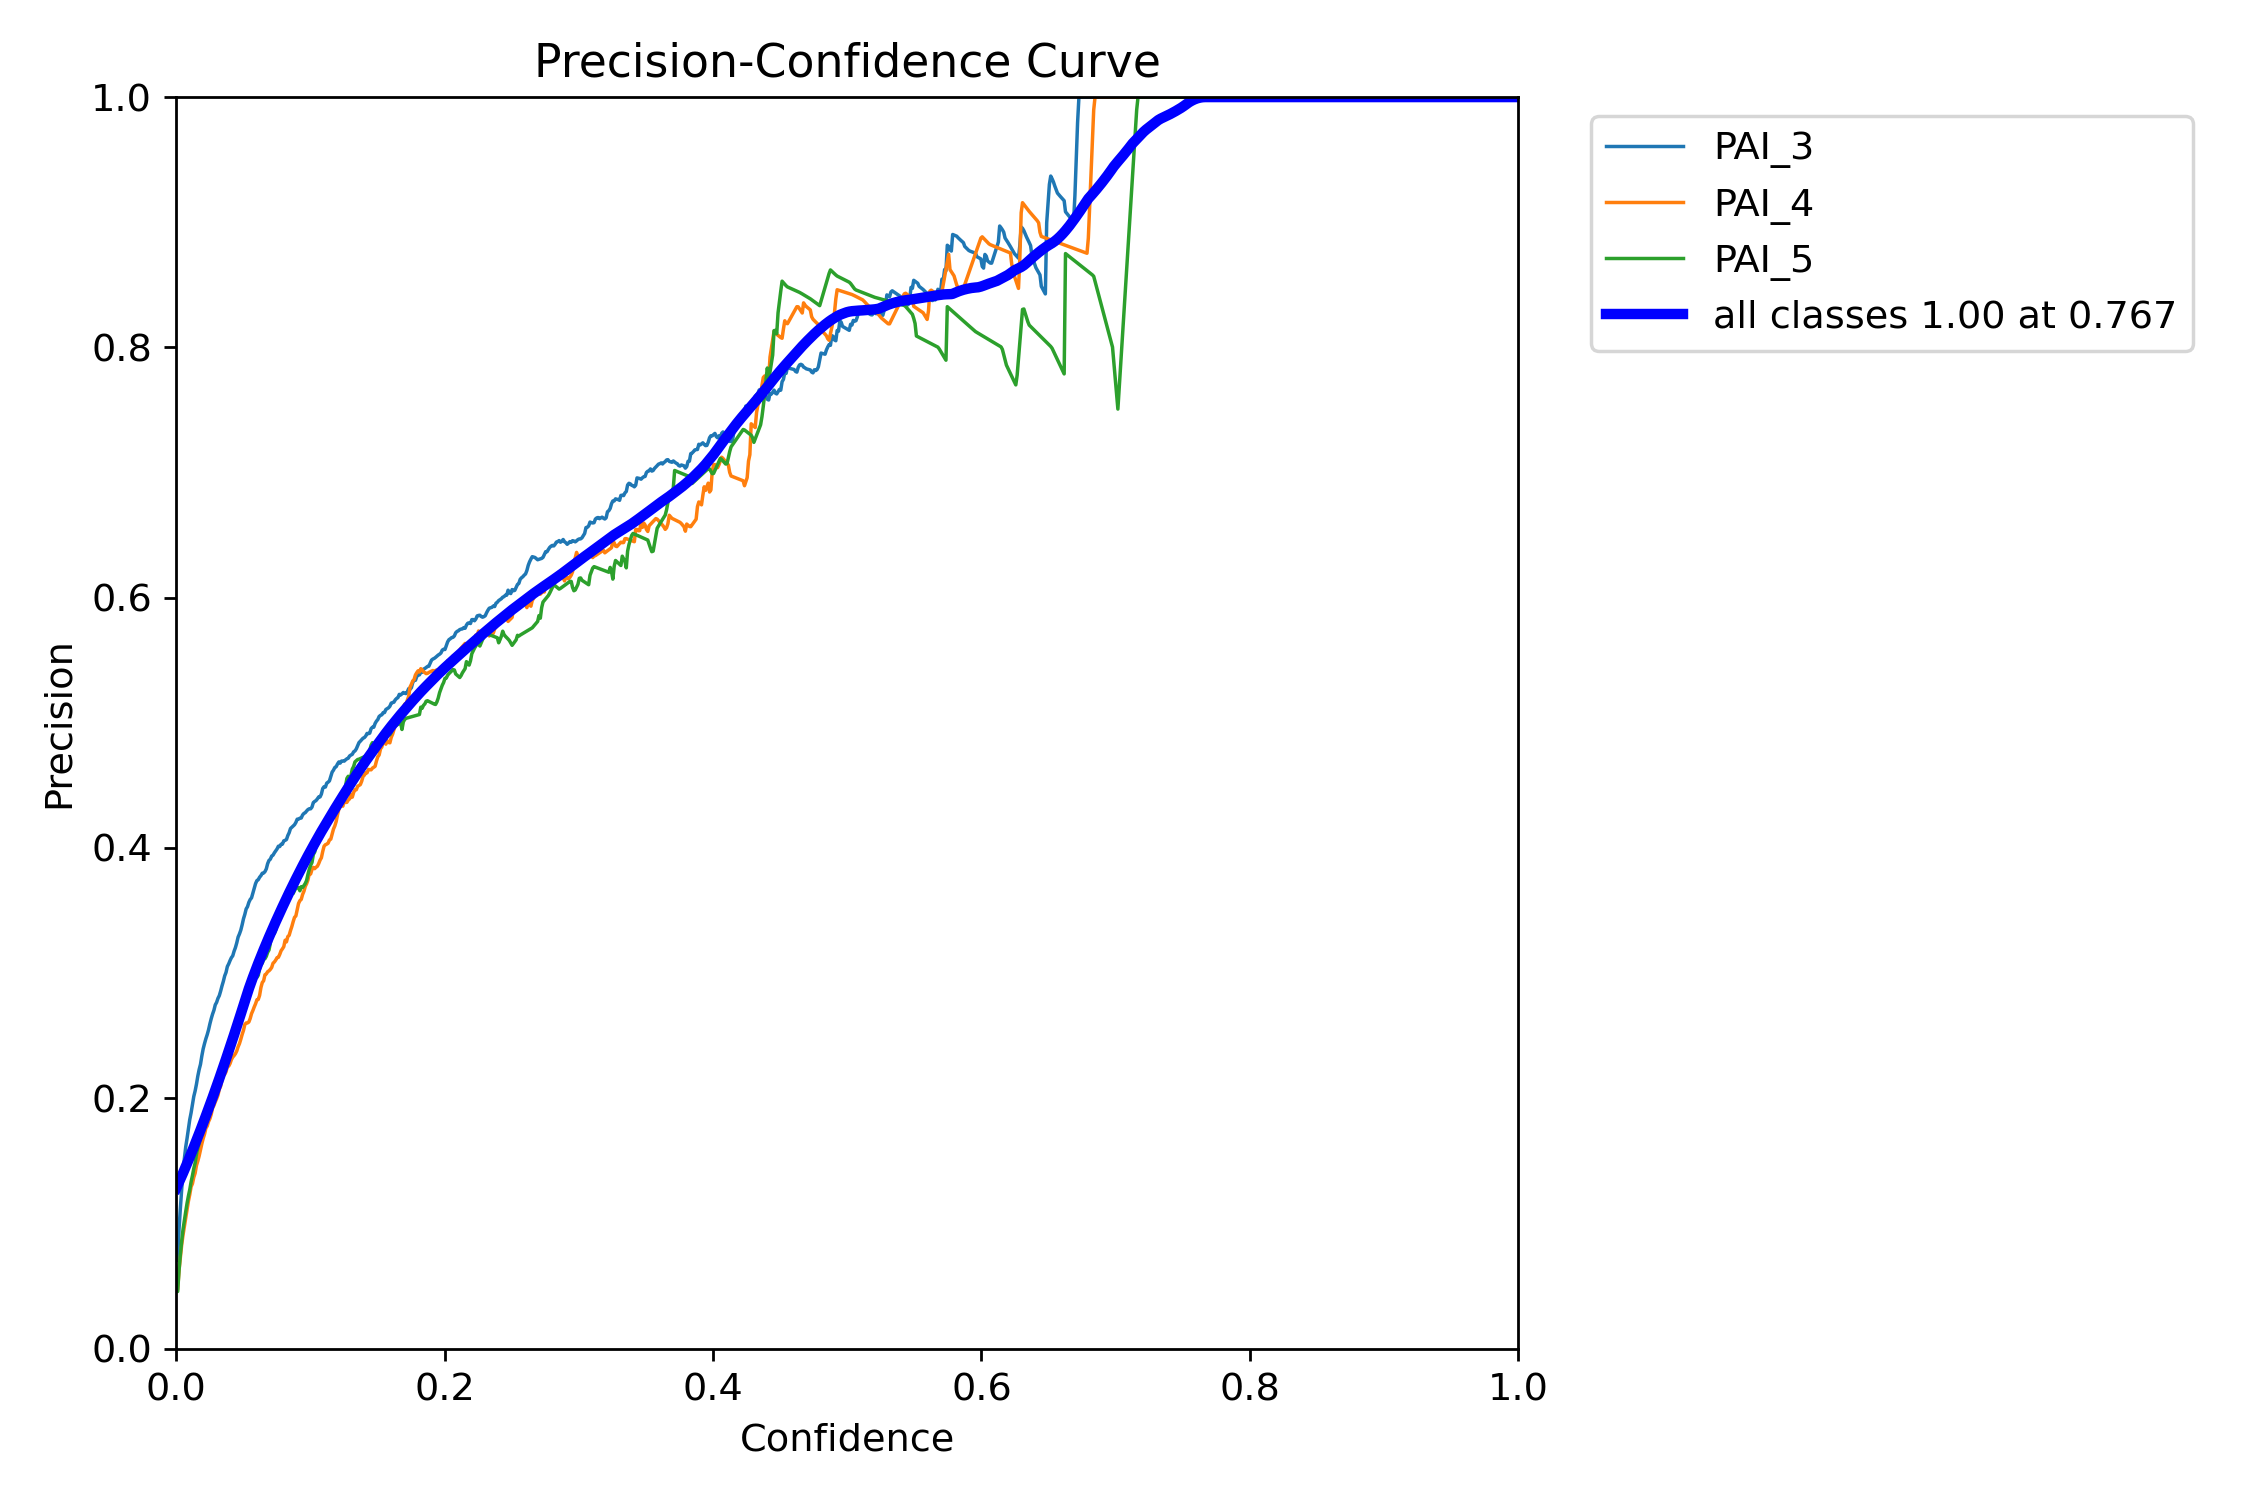


 BoxR_curve.png


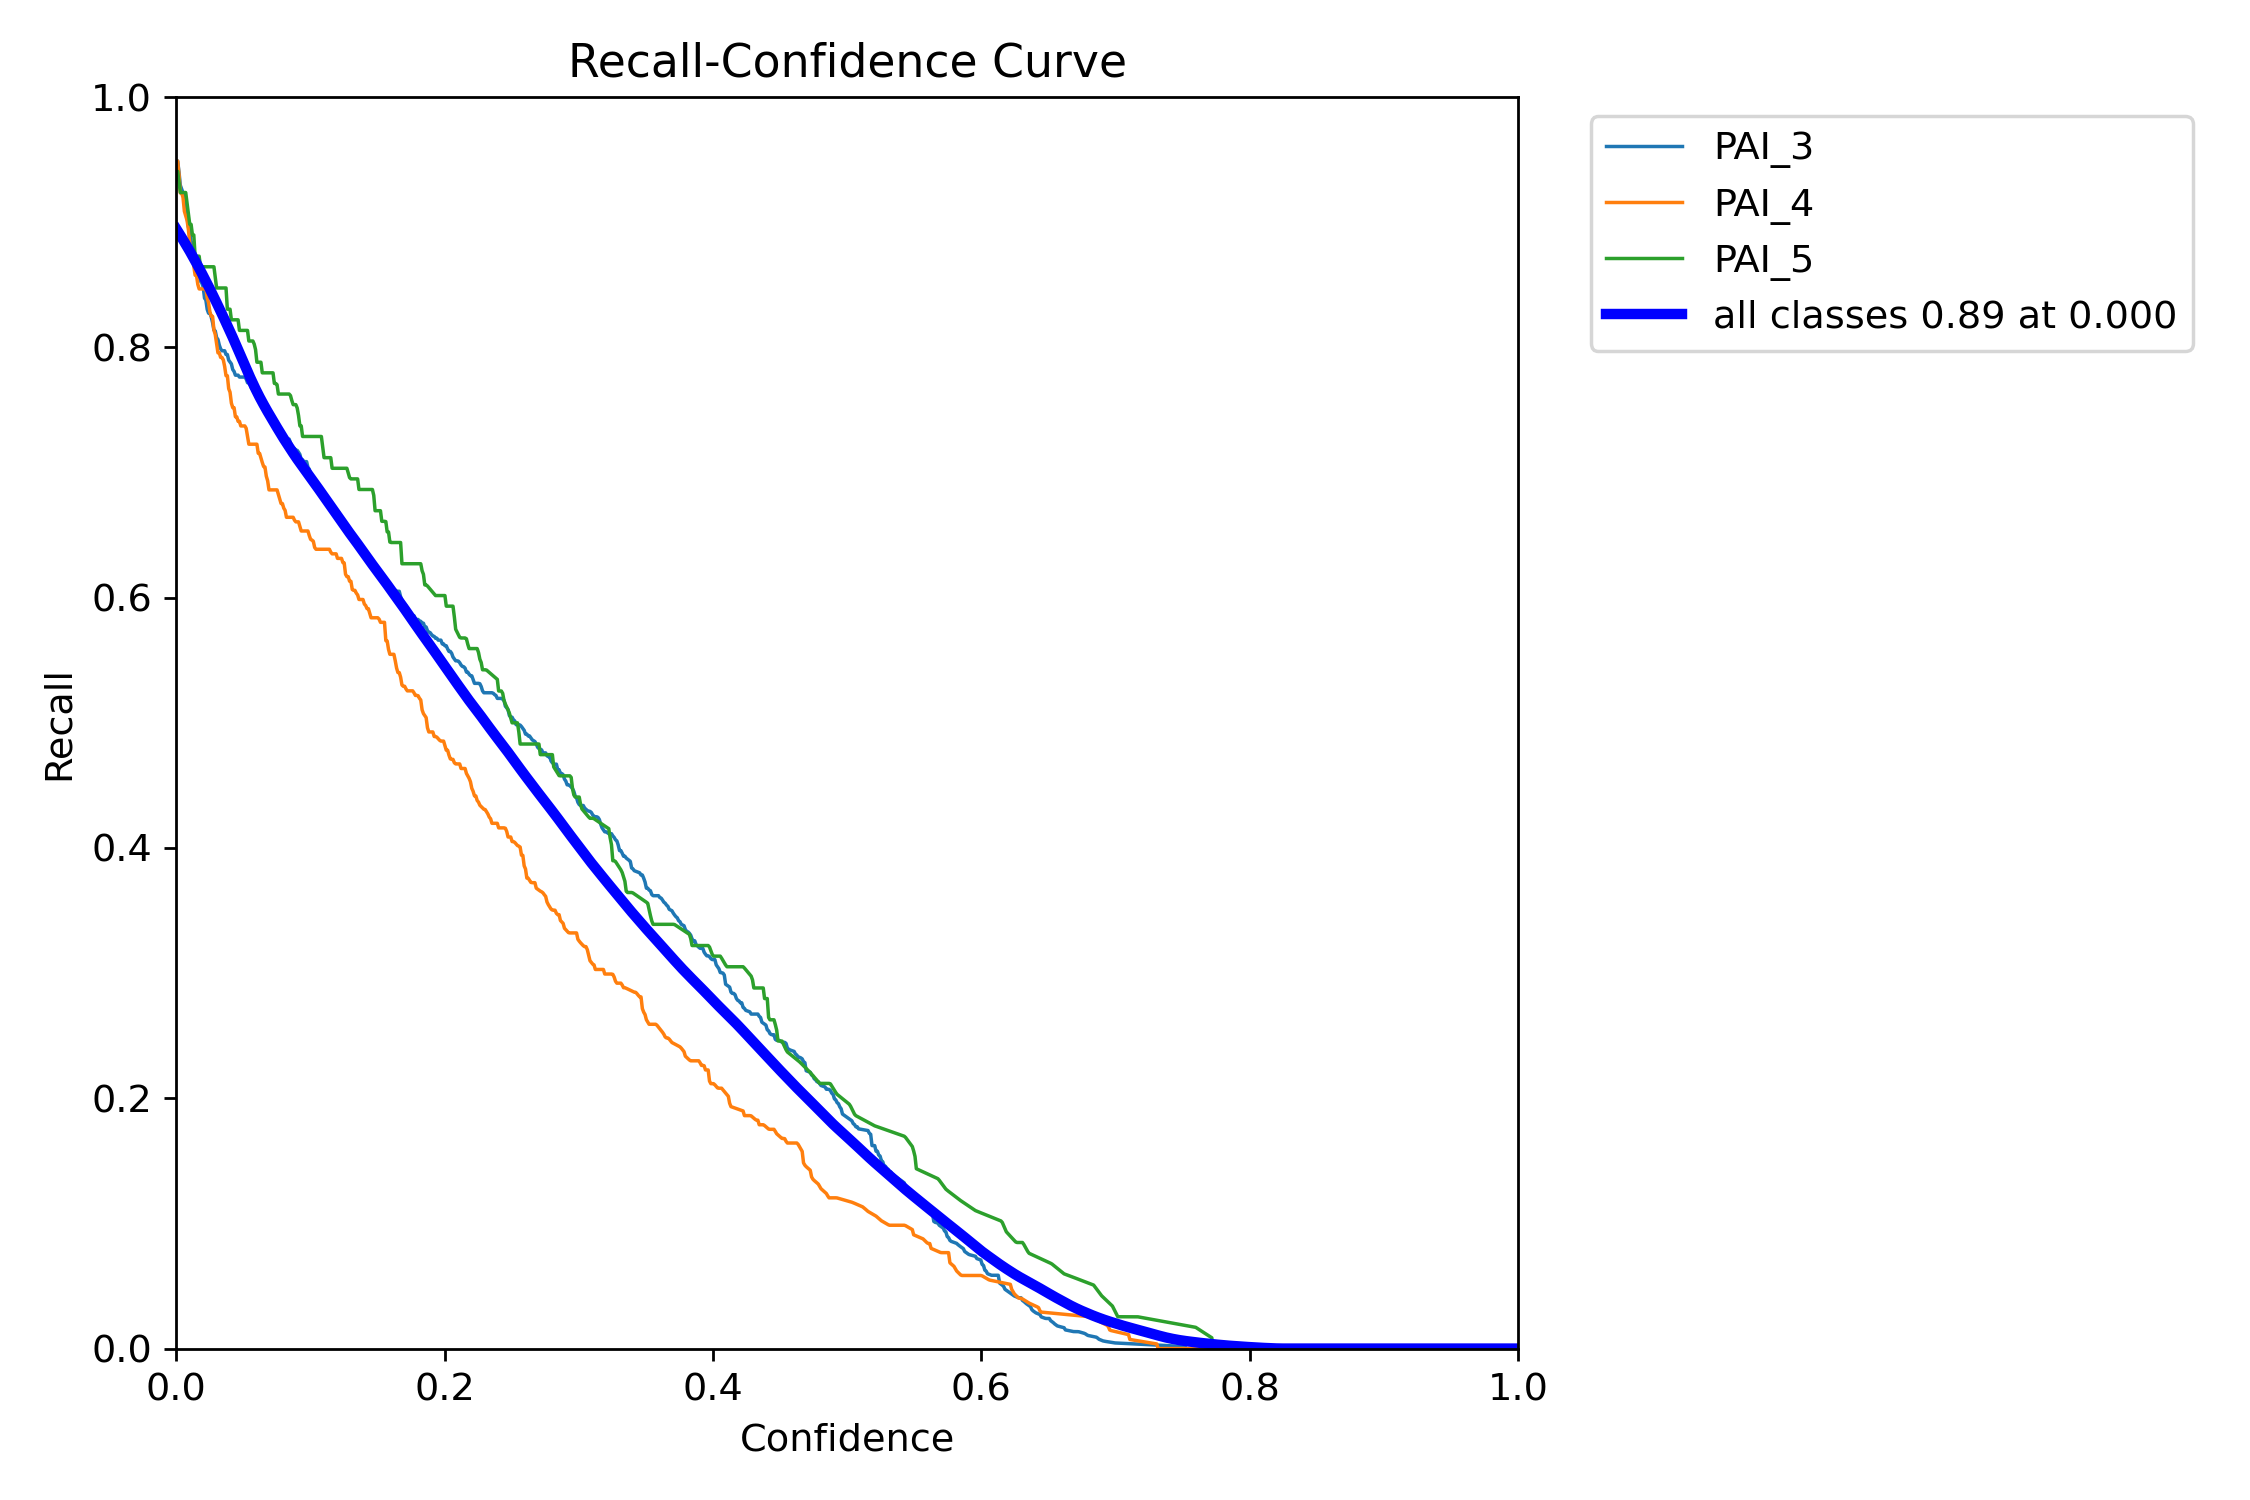


 confusion_matrix_normalized.png


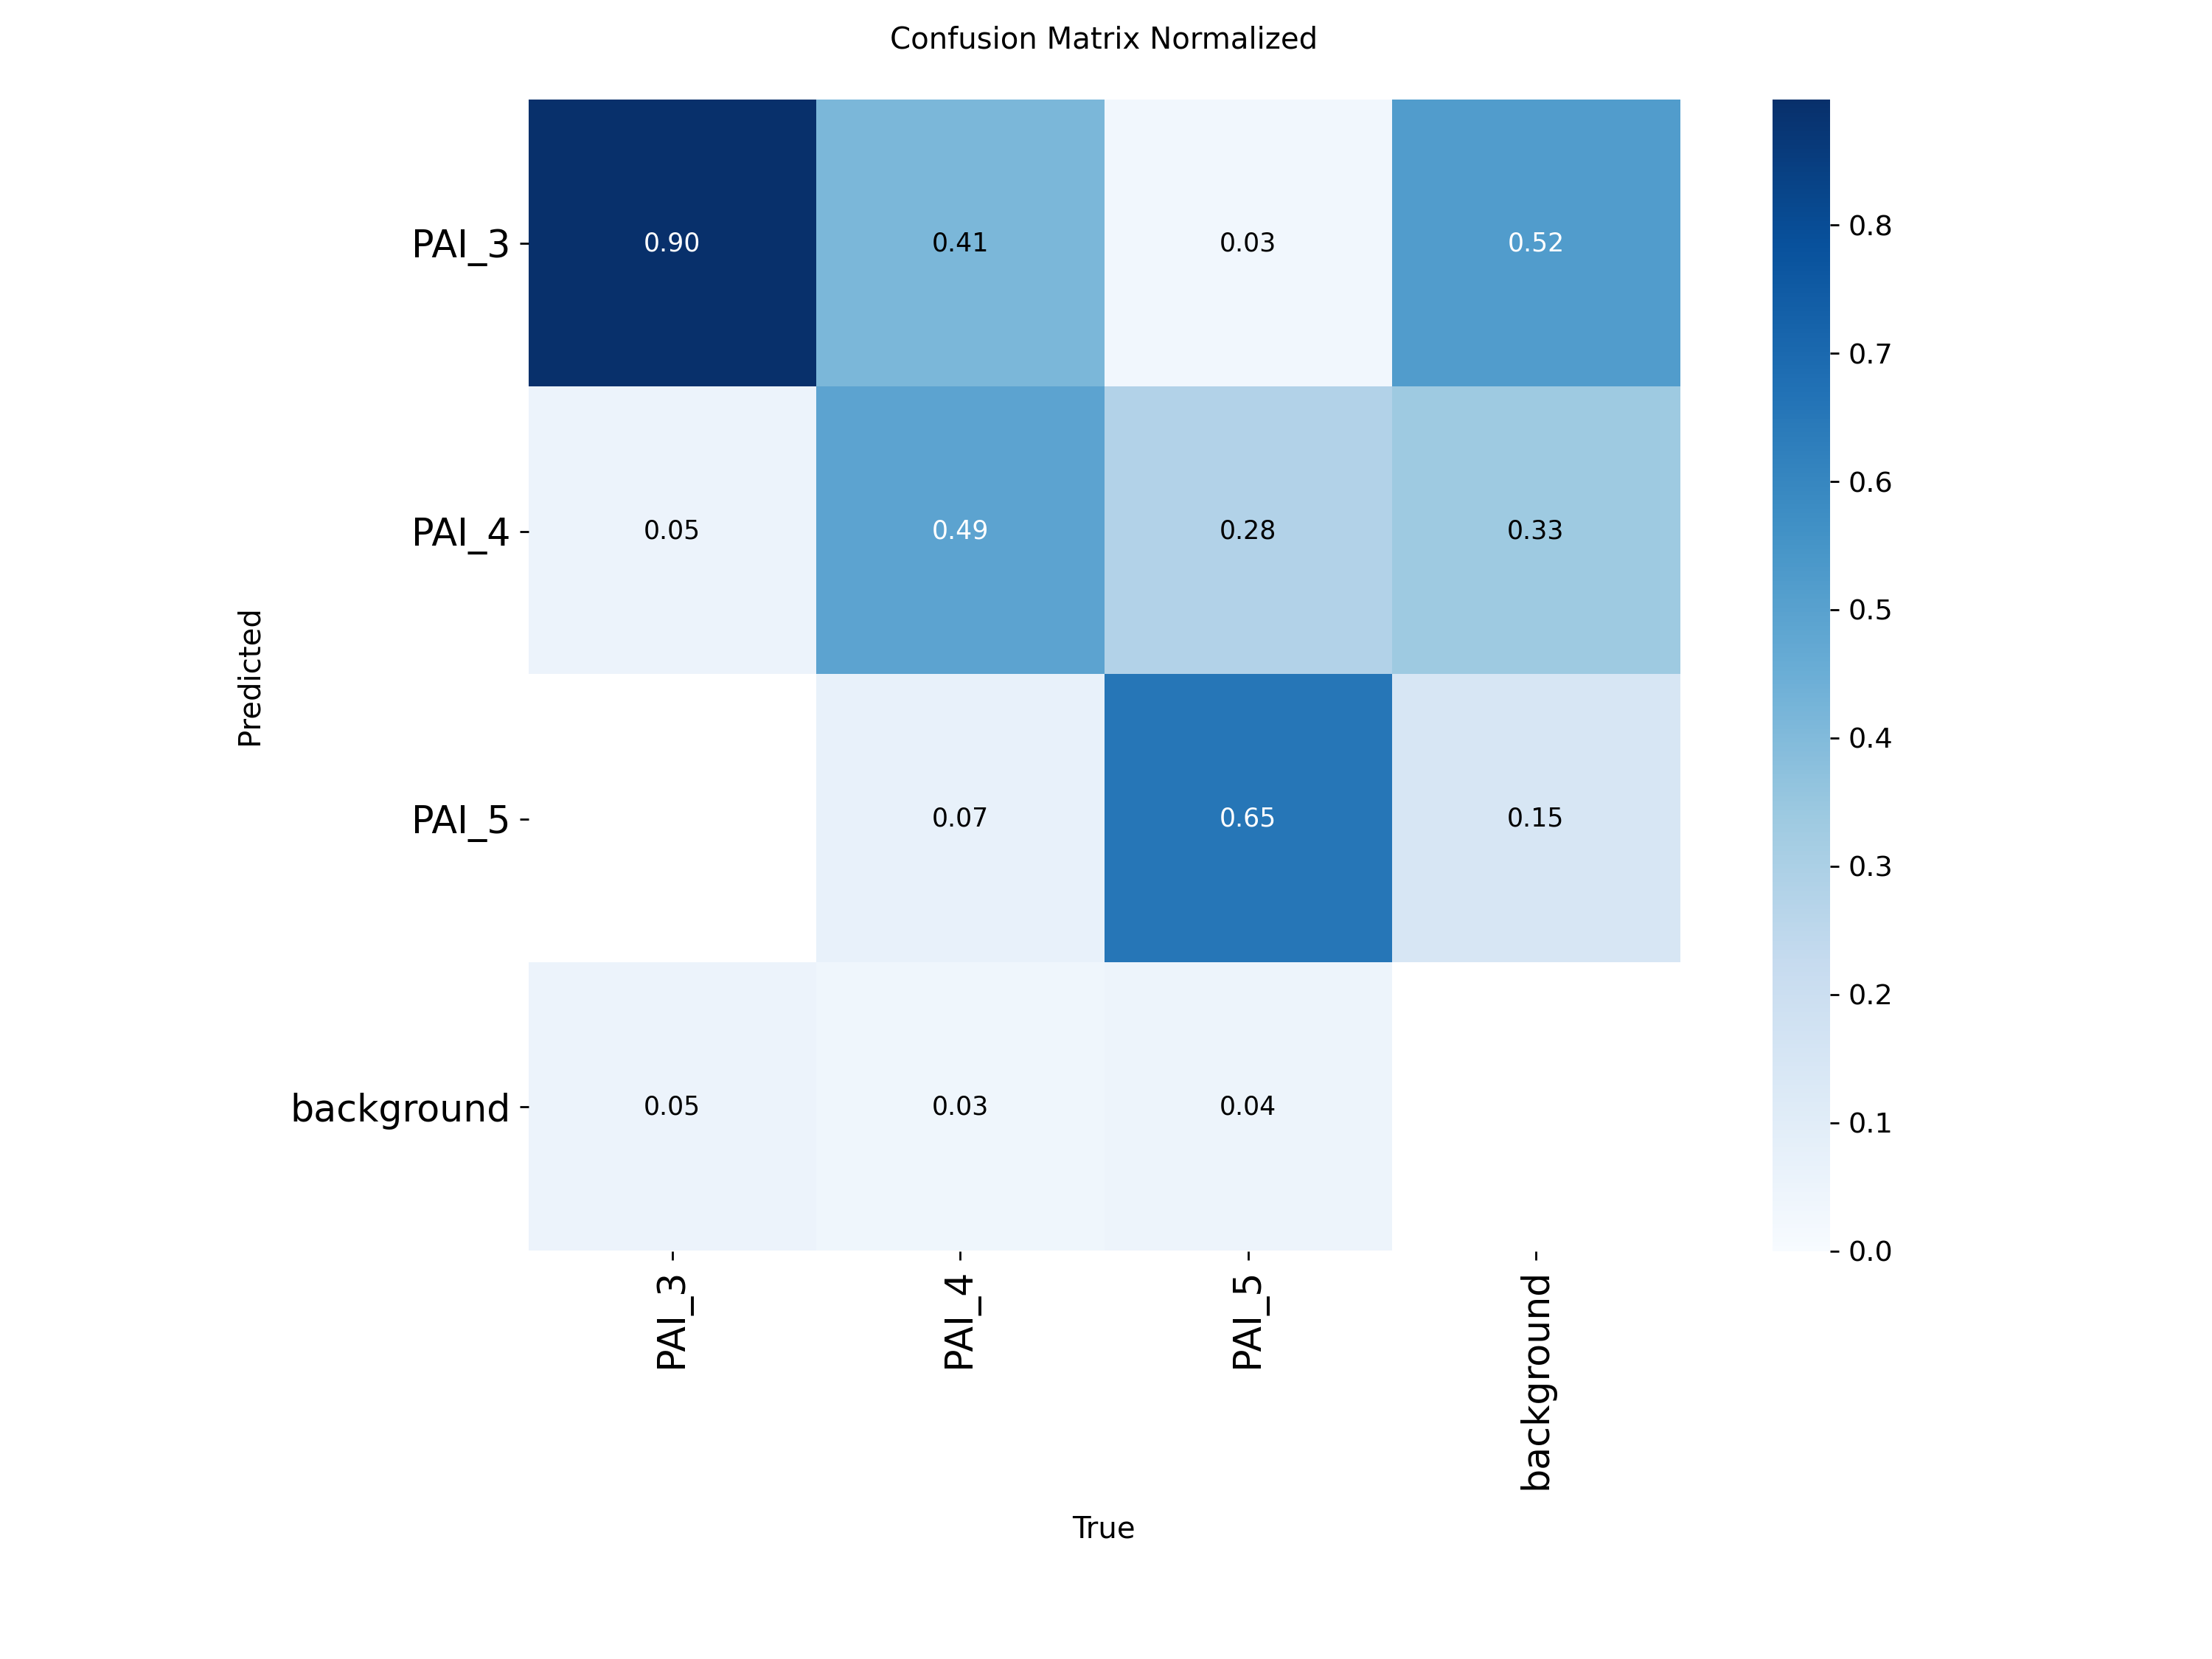

In [ ]:

from IPython.display import display, Image as DisplayImage

#Display YOLO evaluation curves
graphs = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix_normalized.png"
]

for graph in graphs:
    path = YOLO_RESULTS / graph

    if path.exists():
        print("\n", graph)
        display(DisplayImage(filename=str(path)))



0: 1024x1024 1 PAI_4, 1 PAI_5, 13.8ms
1: 1024x1024 (no detections), 13.8ms
2: 1024x1024 2 PAI_3s, 1 PAI_5, 13.8ms
Speed: 13.9ms preprocess, 13.8ms inference, 3.1ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to /content/drive/MyDrive/Dental_Lesion_Detection/models/yolo11_detection/sample_predictions


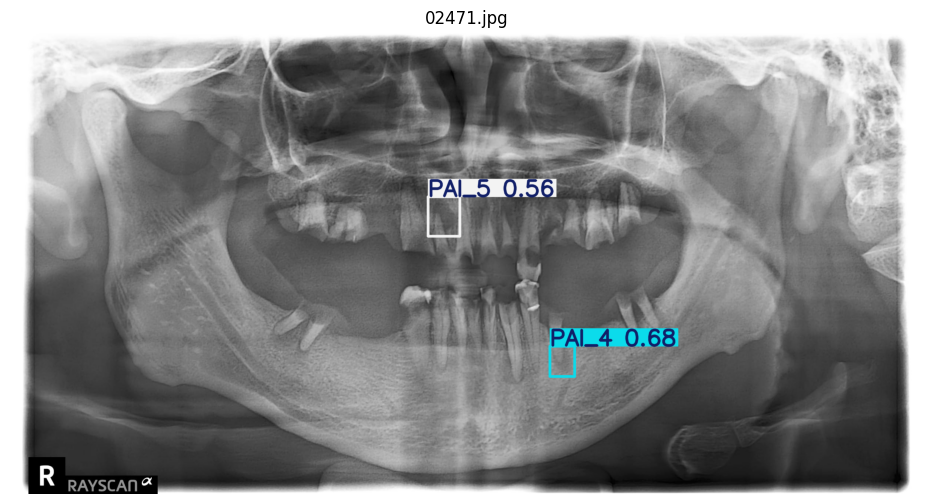

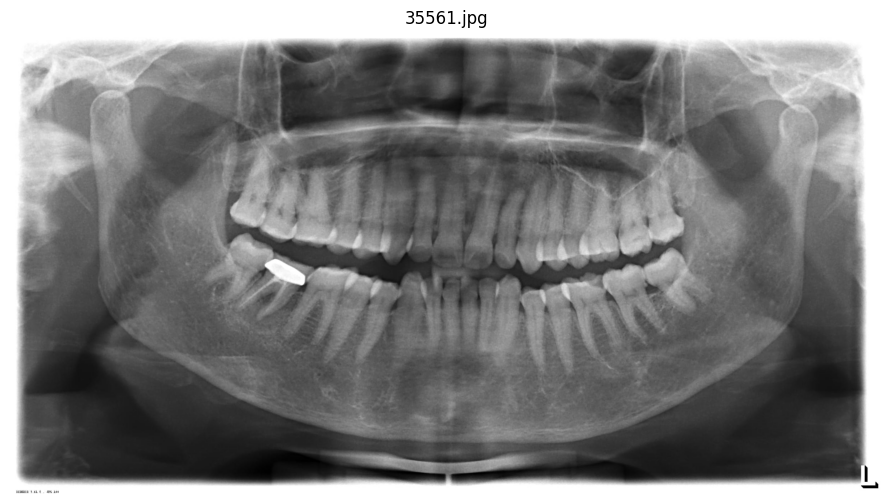

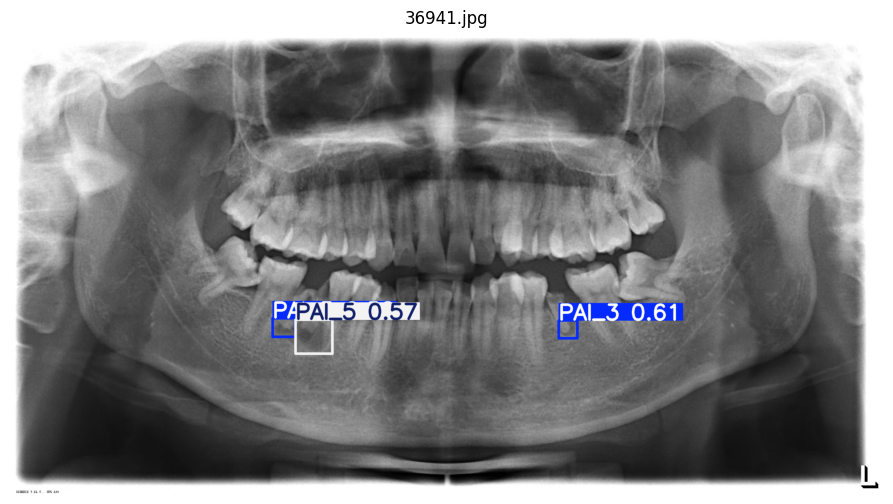

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import random

#Set model and dataset paths
YOLO_RESULTS = Path("/content/drive/MyDrive/Dental_Lesion_Detection/models/yolo11_detection")
YOLO_DIR = Path("/content/yolo_dataset")

#Load best trained model
best_yolo = YOLO(str(YOLO_RESULTS / "weights" / "best.pt"))

#Select random validation images
val_images = list((YOLO_DIR / "images" / "val").glob("*.jpg"))

random.seed(42)
samples = random.sample(val_images, min(3, len(val_images)))

#Predict dental lesions
predictions = best_yolo.predict(
    source=[str(image) for image in samples],
    imgsz=1024,
    conf=0.40,
    device=0,
    save=True,
    project=str(YOLO_RESULTS),
    name="sample_predictions",
    exist_ok=True
)

#Display predictions
for prediction in predictions:
    plt.figure(figsize=(14, 6))
    plt.imshow(prediction.plot()[:, :, ::-1])
    plt.title(Path(prediction.path).name)
    plt.axis("off")
    plt.show()


In [ ]:

from ultralytics import YOLO
from pathlib import Path

#Set project directories
PROJECT_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection")
YOLO_DIR = Path("/content/yolo_dataset")
YOLO_RESULTS = PROJECT_DIR / "models" / "yolo11_detection"

#Check dataset and model
assert (YOLO_DIR / "data.yaml").exists(), "YOLO dataset not found"
assert (YOLO_RESULTS / "weights" / "best.pt").exists(), "Model not found"

#Load best trained model
best_yolo = YOLO(str(YOLO_RESULTS / "weights" / "best.pt"))

#Evaluate on unseen test images
test_results = best_yolo.val(
    data=str(YOLO_DIR / "data.yaml"),
    split="test",
    imgsz=1024,
    batch=8,
    device=0,
    plots=True,
    project=str(YOLO_RESULTS),
    name="final_test",
    exist_ok=True
)

#Display final metrics
print("\nYOLO11 FINAL TEST RESULTS")
print(f"Precision: {test_results.box.mp:.4f}")
print(f"Recall: {test_results.box.mr:.4f}")
print(f"mAP50: {test_results.box.map50:.4f}")
print(f"mAP50-95: {test_results.box.map:.4f}")


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 70.8±35.8 MB/s, size: 211.4 KB)
val: Scanning /content/yolo_dataset/labels/test... 582 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 582/582 242.0it/s 2.4s
val: New cache created: /content/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 3.7it/s 19.7s
                   all        582       1000      0.511       0.53       0.54      0.264
                 PAI_3        421        628      0.556      0.543      0.574      0.255
                 PAI_4        207        269      0.571      0.484      0.556      0.295
                 PAI_5         95        103      0.406      0.563       0.49      0.242
Speed: 2.5ms preprocess, 6.7ms inference, 0.0ms loss, 2.7ms postprocess p

In [ ]:

import pandas as pd

#Create final results table
yolo_test_metrics = pd.DataFrame([{
    "Model": "YOLO11n",
    "Dataset": "Test",
    "Images": 582,
    "Precision": test_results.box.mp,
    "Recall": test_results.box.mr,
    "mAP50": test_results.box.map50,
    "mAP50-95": test_results.box.map
}])

#Save results to Google Drive
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

output_path = RESULTS_DIR / "yolo11_test_results.csv"
yolo_test_metrics.to_csv(output_path, index=False)

print("Results saved:", output_path)
display(yolo_test_metrics)


Results saved: /content/drive/MyDrive/Dental_Lesion_Detection/results/yolo11_test_results.csv


,Model,Dataset,Images,Precision,Recall,mAP50,mAP50-95
0,YOLO11n,Test,582,0.510972,0.530018,0.539869,0.263797


## Evaluation - Deep Learning Classifiers

In [ ]:

import tensorflow as tf
from pathlib import Path

#Set project directories
PROJECT_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection")
MODELS_DIR = PROJECT_DIR / "models"
DATA_DIR = PROJECT_DIR / "dataset" / "lesion_crops"

#Check test dataset
TEST_DIR = DATA_DIR / "test"

print("Test folder exists:", TEST_DIR.exists())
print("ResNet50 exists:", (MODELS_DIR / "resnet50.keras").exists())

#Count test images
for class_name in ["3", "4", "5"]:
    class_dir = TEST_DIR / class_name
    print(f"PAI {class_name}:", len(list(class_dir.glob("*.jpg"))))


Test folder exists: True
ResNet50 exists: True
PAI 3: 628
PAI 4: 269
PAI 5: 103


Total test images: 1000
PAI 3: 628
PAI 4: 269
PAI 5: 103
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 472ms/step

RESNET50 FINAL TEST RESULTS
Accuracy: 0.7860
Macro Precision: 0.7501
Macro Recall: 0.7294
Macro F1: 0.7373

Classification Report:
              precision    recall  f1-score   support

       PAI 3       0.89      0.86      0.87       628
       PAI 4       0.59      0.67      0.63       269
       PAI 5       0.77      0.66      0.71       103

    accuracy                           0.79      1000
   macro avg       0.75      0.73      0.74      1000
weighted avg       0.80      0.79      0.79      1000



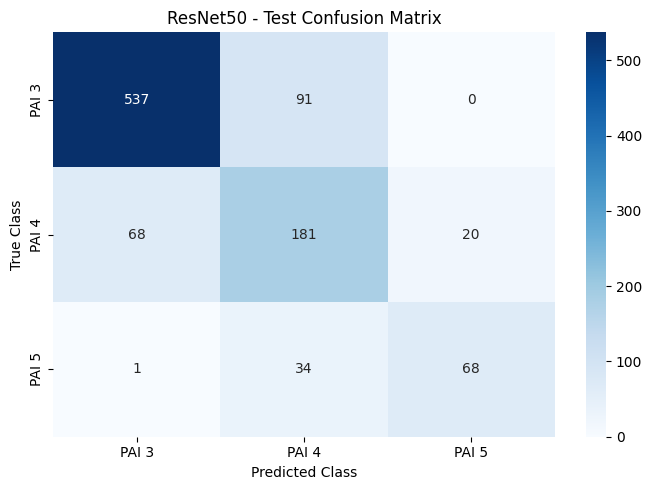


Final results saved successfully!


,Model,Dataset,Images,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ResNet50,Test,1000,0.786,0.750123,0.729384,0.737316


In [ ]:

#RESNET50 - FINAL TEST EVALUATION

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tensorflow.keras.applications.resnet50 import preprocess_input

#Set project directories
PROJECT_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection")
MODELS_DIR = PROJECT_DIR / "models"
TEST_DIR = PROJECT_DIR / "dataset" / "lesion_crops" / "test"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

#Define classes
class_names = ["3", "4", "5"]

#Collect only images from class folders
image_paths = []
labels = []

for class_id, class_name in enumerate(class_names):
    folder = TEST_DIR / class_name

    for image_path in sorted(folder.glob("*.jpg")):
        image_paths.append(str(image_path))
        labels.append(class_id)

#Verify dataset
print("Total test images:", len(image_paths))

for class_id, class_name in enumerate(class_names):
    print(f"PAI {class_name}:", labels.count(class_id))

assert len(image_paths) == 1000, "Incorrect test dataset size"
assert [labels.count(i) for i in range(3)] == [628, 269, 103]

#Load and resize images
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (128, 128))
    return image, label

#Create test dataset
test_ds = tf.data.Dataset.from_tensor_slices(
    (image_paths, labels)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)

#Load trained ResNet50
model_resnet_best = tf.keras.models.load_model(
    MODELS_DIR / "resnet50.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

#Predict test images
y_true = np.array(labels)
y_prob = model_resnet_best.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

#Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

#Display final results
print("\nRESNET50 FINAL TEST RESULTS")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["PAI 3", "PAI 4", "PAI 5"],
    zero_division=0
))

#Create confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["PAI 3", "PAI 4", "PAI 5"],
    yticklabels=["PAI 3", "PAI 4", "PAI 5"]
)

plt.title("ResNet50 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

#Save confusion matrix
plt.savefig(
    RESULTS_DIR / "resnet50_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Save final metrics
results_df = pd.DataFrame([{
    "Model": "ResNet50",
    "Dataset": "Test",
    "Images": len(image_paths),
    "Accuracy": accuracy,
    "Macro Precision": precision,
    "Macro Recall": recall,
    "Macro F1": macro_f1
}])

results_df.to_csv(
    RESULTS_DIR / "resnet50_test_results.csv",
    index=False
)

#Save classification report
report_df = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=["PAI 3", "PAI 4", "PAI 5"],
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    RESULTS_DIR / "resnet50_classification_report.csv"
)

print("\nFinal results saved successfully!")
display(results_df)


In [ ]:

#Check saved previous models

model_files = [
    "custom_cnn.keras",
    "mobilenet_v2.keras",
    "mobilenet_v2_finetuned.keras",
    "mobilenet_v2_augmented.keras"
]

for filename in model_files:
    model_path = MODELS_DIR / filename

    if model_path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")


FOUND: custom_cnn.keras
FOUND: mobilenet_v2.keras
FOUND: mobilenet_v2_finetuned.keras
FOUND: mobilenet_v2_augmented.keras


## Final Test Evaluation - CNN Models Comparison

In [ ]:

#FINAL TEST EVALUATION - CNN MODELS

import tensorflow as tf
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

#Define saved models
models_to_evaluate = {
    "Custom CNN": "custom_cnn.keras",
    "MobileNetV2": "mobilenet_v2.keras",
    "MobileNetV2 Fine-Tuned": "mobilenet_v2_finetuned.keras",
    "MobileNetV2 Augmented": "mobilenet_v2_augmented.keras"
}

#Use the corrected test dataset
assert len(image_paths) == 1000, "Incorrect test dataset"
y_true = np.array(labels)

#Store evaluation results
all_results = []

for model_name, filename in models_to_evaluate.items():

    print(f"\nEvaluating: {model_name}")

    #Load trained model
    model = tf.keras.models.load_model(
        MODELS_DIR / filename,
        compile=False
    )

    #Predict test images
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    #Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    #Store results
    all_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

    #Free model memory
    del model
    tf.keras.backend.clear_session()

#Create comparison table
comparison_df = pd.DataFrame(all_results)

#Add ResNet50 final results
comparison_df.loc[len(comparison_df)] = {
    "Model": "ResNet50",
    "Accuracy": 0.7860,
    "Macro Precision": 0.7501,
    "Macro Recall": 0.7294,
    "Macro F1": 0.7373
}

#Sort by Macro F1
comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

#Save comparison results
comparison_df.to_csv(
    RESULTS_DIR / "deep_learning_test_comparison.csv",
    index=False
)

print("\nFINAL DEEP LEARNING COMPARISON")
display(comparison_df)



Evaluating: Custom CNN
Accuracy: 0.6610
Macro F1: 0.3757

Evaluating: MobileNetV2
Accuracy: 0.7380
Macro F1: 0.7013

Evaluating: MobileNetV2 Fine-Tuned
Accuracy: 0.7870
Macro F1: 0.7476

Evaluating: MobileNetV2 Augmented
Accuracy: 0.6920
Macro F1: 0.6627

FINAL DEEP LEARNING COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,MobileNetV2 Fine-Tuned,0.787,0.734024,0.769592,0.747597
1,ResNet50,0.786,0.750100,0.729400,0.737300
2,MobileNetV2,0.738,0.683844,0.734247,0.701280
3,MobileNetV2 Augmented,0.692,0.641821,0.742040,0.662674
4,Custom CNN,0.661,0.383660,0.399019,0.375673


## Error Analysis


Custom CNN
              precision    recall  f1-score   support

       PAI 3       0.70      0.94      0.80       628
       PAI 4       0.45      0.25      0.32       269
       PAI 5       0.00      0.00      0.00       103

    accuracy                           0.66      1000
   macro avg       0.38      0.40      0.38      1000
weighted avg       0.56      0.66      0.59      1000


MobileNetV2
              precision    recall  f1-score   support

       PAI 3       0.91      0.76      0.83       628
       PAI 4       0.52      0.66      0.58       269
       PAI 5       0.62      0.78      0.69       103

    accuracy                           0.74      1000
   macro avg       0.68      0.73      0.70      1000
weighted avg       0.77      0.74      0.75      1000


MobileNetV2 Fine-Tuned
              precision    recall  f1-score   support

       PAI 3       0.93      0.82      0.87       628
       PAI 4       0.59      0.72      0.65       269
       PAI 5       0.69   

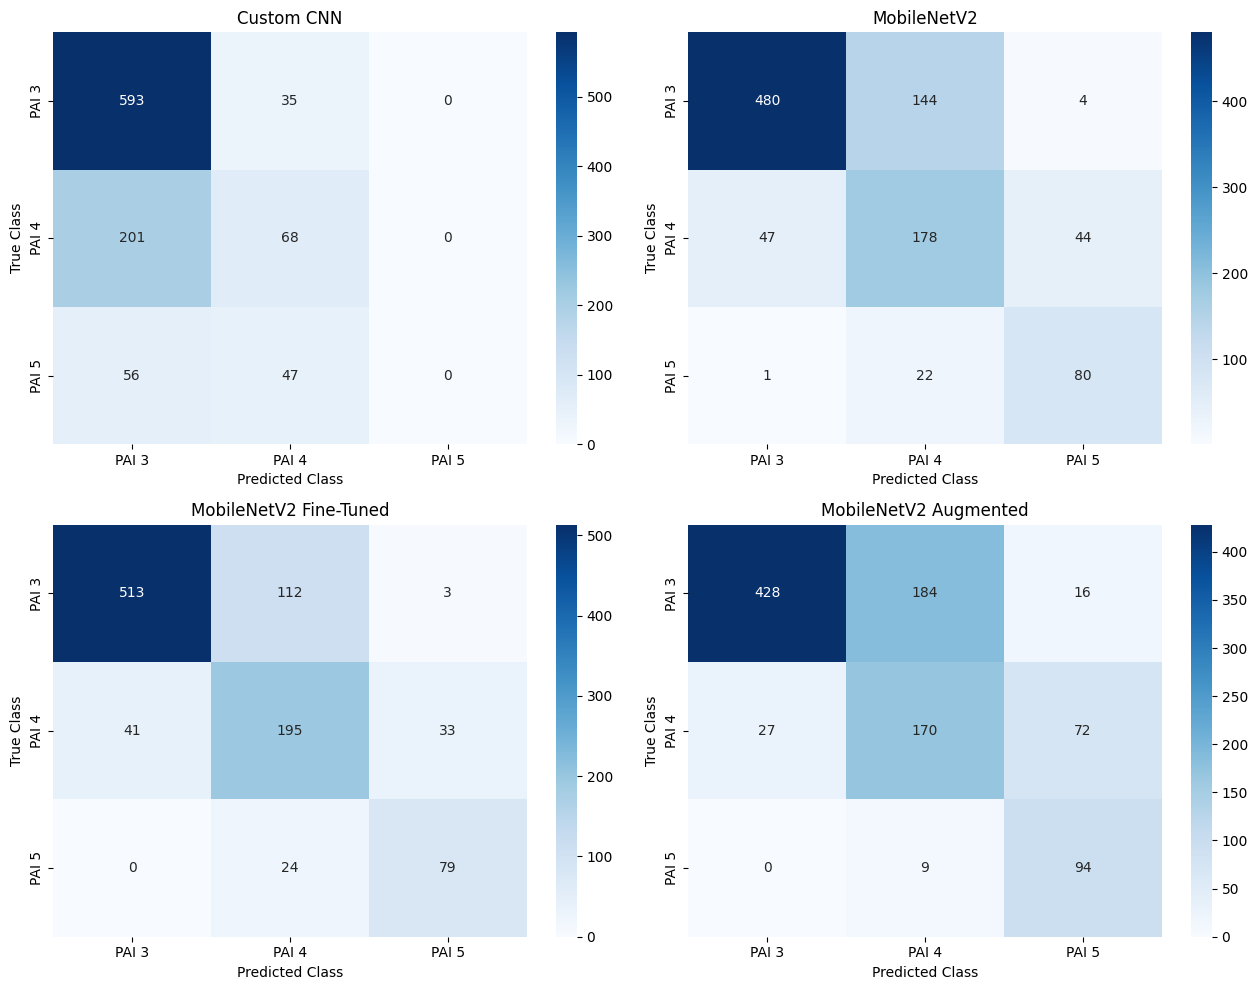

In [ ]:

#DEEP LEARNING - ERROR ANALYSIS

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

class_labels = ["PAI 3", "PAI 4", "PAI 5"]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

#Analyze each trained model
for ax, (model_name, filename) in zip(
    axes.flatten(), models_to_evaluate.items()
):

    #Load model
    model = tf.keras.models.load_model(
        MODELS_DIR / filename,
        compile=False
    )

    #Predict test images
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    #Calculate confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

    #Display classification report
    print(f"\n{model_name}")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_labels,
        zero_division=0
    ))

    #Save classification report
    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_labels,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        RESULTS_DIR / f"{Path(filename).stem}_test_report.csv"
    )

    del model
    tf.keras.backend.clear_session()

#Save comparison figure
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "cnn_test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Custom CNN Diagnostics

In [ ]:

#CUSTOM CNN - MODEL DIAGNOSTICS

import tensorflow as tf

#Load saved CNN
custom_model = tf.keras.models.load_model(
    MODELS_DIR / "custom_cnn.keras",
    compile=False
)

#Inspect model architecture
custom_model.summary()

#Inspect preprocessing layers
print("\nMODEL LAYERS")

for layer in custom_model.layers:
    print(layer.name, type(layer).__name__)

    if isinstance(layer, tf.keras.layers.Rescaling):
        print("Scale:", layer.scale)
        print("Offset:", layer.offset)

#Inspect test image values
for images, batch_labels in test_ds.take(1):
    print("\nTEST IMAGE INFORMATION")
    print("Shape:", images.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Mean pixel value:", tf.reduce_mean(images).numpy())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


MODEL LAYERS
rescaling Rescaling
Scale: 0.00392156862745098
Offset: 0.0
conv2d Conv2D
max_pooling2d MaxPooling2D
conv2d_1 Conv2D
max_pooling2d_1 MaxPooling2D
conv2d_2 Conv2D
max_pooling2d_2 MaxPooling2D
flatten Flatten
dense Dense
dropout Dropout
dense_1 Dense

TEST IMAGE INFORMATION
Shape: (32, 128, 128, 3)
Minimum pixel value: 34.0
Maximum pixel value: 217.0
Mean pixel value: 110.58905


In [ ]:

#CUSTOM CNN - VALIDATION CHECK

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

#Set validation directory
VAL_DIR = PROJECT_DIR / "dataset" / "lesion_crops" / "validation"

#Collect validation images
val_paths = []
val_labels = []

for class_id, class_name in enumerate(["3", "4", "5"]):
    for image_path in sorted((VAL_DIR / class_name).glob("*.jpg")):
        val_paths.append(str(image_path))
        val_labels.append(class_id)

#Verify validation dataset
print("Total validation images:", len(val_paths))

for i in range(3):
    print(f"PAI {i + 3}:", val_labels.count(i))

assert [val_labels.count(i) for i in range(3)] == [666, 274, 118]

#Create validation dataset
val_check_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_check_ds = val_check_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_check_ds = val_check_ds.batch(32).prefetch(tf.data.AUTOTUNE)

#Evaluate saved model
val_prob = custom_model.predict(val_check_ds)
val_pred = np.argmax(val_prob, axis=1)

#Calculate validation metrics
print("\nCUSTOM CNN - VALIDATION RESULTS")
print("Accuracy:", accuracy_score(val_labels, val_pred))
print("Macro F1:", f1_score(val_labels, val_pred, average="macro"))

print(classification_report(
    val_labels,
    val_pred,
    labels=[0, 1, 2],
    target_names=["PAI 3", "PAI 4", "PAI 5"],
    zero_division=0
))


Total validation images: 1058
PAI 3: 666
PAI 4: 274
PAI 5: 118
34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step

CUSTOM CNN - VALIDATION RESULTS
Accuracy: 0.665406427221172
Macro F1: 0.36912821773054
              precision    recall  f1-score   support

       PAI 3       0.70      0.97      0.81       666
       PAI 4       0.45      0.22      0.30       274
       PAI 5       0.00      0.00      0.00       118

    accuracy                           0.67      1058
   macro avg       0.38      0.40      0.37      1058
weighted avg       0.56      0.67      0.59      1058



In [ ]:

#CHECK MODELS IN MEMORY

for name, obj in list(globals().items()):

    if isinstance(obj, tf.keras.Model):
        print(
            f"Variable: {name} | "
            f"Model: {obj.name} | "
            f"Parameters: {obj.count_params():,}"
        )

Variable: model_cnn | Model: sequential | Parameters: 3,305,027
Variable: base_model | Model: mobilenetv2_1.00_128 | Parameters: 2,257,984
Variable: model_mobilenet | Model: functional_1 | Parameters: 2,261,827
Variable: model_finetuned | Model: functional_1 | Parameters: 2,261,827
Variable: data_augmentation | Model: sequential_1 | Parameters: 0
Variable: base_aug | Model: mobilenetv2_1.00_128 | Parameters: 2,257,984
Variable: model_aug | Model: functional_3 | Parameters: 2,261,827
Variable: model_aug_best | Model: functional_3 | Parameters: 2,261,827
Variable: base_resnet | Model: resnet50 | Parameters: 23,587,712
Variable: model_resnet | Model: functional_8 | Parameters: 23,593,859
Variable: model_resnet_best | Model: functional_8 | Parameters: 23,593,859
Variable: custom_model | Model: sequential | Parameters: 3,305,027


In [ ]:

#COMPARE CUSTOM CNN WEIGHTS

import numpy as np

original_weights = model_cnn.get_weights()
saved_weights = custom_model.get_weights()

#Compare model weights
same_weights = all(
    np.array_equal(w1, w2)
    for w1, w2 in zip(original_weights, saved_weights)
)

print("Same weights:", same_weights)

#Calculate maximum weight difference
max_difference = max(
    np.max(np.abs(w1 - w2))
    for w1, w2 in zip(original_weights, saved_weights)
)

print("Maximum weight difference:", max_difference)


Same weights: True
Maximum weight difference: 0.0


In [ ]:

#ORIGINAL CUSTOM CNN - VALIDATION CHECK

#Predict validation images
original_prob = model_cnn.predict(val_check_ds)
original_pred = np.argmax(original_prob, axis=1)

#Calculate metrics
original_accuracy = accuracy_score(val_labels, original_pred)
original_f1 = f1_score(
    val_labels, original_pred, average="macro"
)

print("\nORIGINAL CUSTOM CNN RESULTS")
print(f"Accuracy: {original_accuracy:.4f}")
print(f"Macro F1: {original_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    val_labels,
    original_pred,
    labels=[0, 1, 2],
    target_names=["PAI 3", "PAI 4", "PAI 5"],
    zero_division=0
))


34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step

ORIGINAL CUSTOM CNN RESULTS
Accuracy: 0.6654
Macro F1: 0.3691

Classification Report:
              precision    recall  f1-score   support

       PAI 3       0.70      0.97      0.81       666
       PAI 4       0.45      0.22      0.30       274
       PAI 5       0.00      0.00      0.00       118

    accuracy                           0.67      1058
   macro avg       0.38      0.40      0.37      1058
weighted avg       0.56      0.67      0.59      1058



In [ ]:

#FIND TRAINING HISTORIES

for name, obj in list(globals().items()):

    if isinstance(obj, tf.keras.callbacks.History):
        print(f"\nHistory variable: {name}")
        print("Available metrics:", list(obj.history.keys()))

        if "val_accuracy" in obj.history:
            print("Best validation accuracy:",
                  max(obj.history["val_accuracy"]))

        if "val_loss" in obj.history:
            best_epoch = np.argmin(obj.history["val_loss"]) + 1

            print("Best validation loss:",
                  min(obj.history["val_loss"]))
            print("Best epoch by validation loss:", best_epoch)

            if "val_accuracy" in obj.history:
                print("Accuracy at best loss epoch:",
                      obj.history["val_accuracy"][best_epoch - 1])



History variable: history_cnn
Available metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Best validation accuracy: 0.6654064059257507
Best validation loss: 0.7659005522727966
Best epoch by validation loss: 20
Accuracy at best loss epoch: 0.6654064059257507

History variable: history_mobilenet
Available metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Best validation accuracy: 0.7551984786987305
Best validation loss: 0.5441396236419678
Best epoch by validation loss: 1
Accuracy at best loss epoch: 0.7504726052284241

History variable: history_finetune
Available metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Best validation accuracy: 0.7863894104957581
Best validation loss: 0.4798578917980194
Best epoch by validation loss: 9
Accuracy at best loss epoch: 0.7769376039505005

History variable: history_aug
Available metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Best validation accuracy: 0.7145557403564453
Best validation loss: 0.6958698630332947
Best 

In [ ]:

#FINAL VALIDATION CONSISTENCY CHECK

import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from tensorflow.keras.applications.resnet50 import preprocess_input

#Define saved models
validation_models = {
    "Custom CNN": "custom_cnn.keras",
    "MobileNetV2": "mobilenet_v2.keras",
    "MobileNetV2 Fine-Tuned": "mobilenet_v2_finetuned.keras",
    "MobileNetV2 Augmented": "mobilenet_v2_augmented.keras",
    "ResNet50": "resnet50.keras"
}

#Verify validation dataset
assert len(val_paths) == 1058
assert [val_labels.count(i) for i in range(3)] == [666, 274, 118]

validation_results = []

#Evaluate saved models
for model_name, filename in validation_models.items():

    print(f"\nEvaluating: {model_name}")

    model = tf.keras.models.load_model(
        MODELS_DIR / filename,
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )

    #Predict validation images
    probabilities = model.predict(val_check_ds, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    #Calculate metrics
    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(val_labels, predictions),
        "Macro Precision": precision_score(
            val_labels, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            val_labels, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            val_labels, predictions, average="macro", zero_division=0
        )
    })

    del model
    tf.keras.backend.clear_session()

#Create validation comparison table
validation_df = pd.DataFrame(validation_results)

validation_df = validation_df.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

#Save verified results
validation_df.to_csv(
    RESULTS_DIR / "deep_learning_validation_verified.csv",
    index=False
)

display(validation_df)


Evaluating: Custom CNN

Evaluating: MobileNetV2

Evaluating: MobileNetV2 Fine-Tuned

Evaluating: MobileNetV2 Augmented

Evaluating: ResNet50


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ResNet50,0.808129,0.757000,0.745618,0.751104
1,MobileNetV2 Fine-Tuned,0.776938,0.728180,0.738575,0.732940
2,MobileNetV2,0.750473,0.707853,0.728857,0.715406
3,MobileNetV2 Augmented,0.714556,0.666790,0.751500,0.689478
4,Custom CNN,0.665406,0.381975,0.396031,0.369128


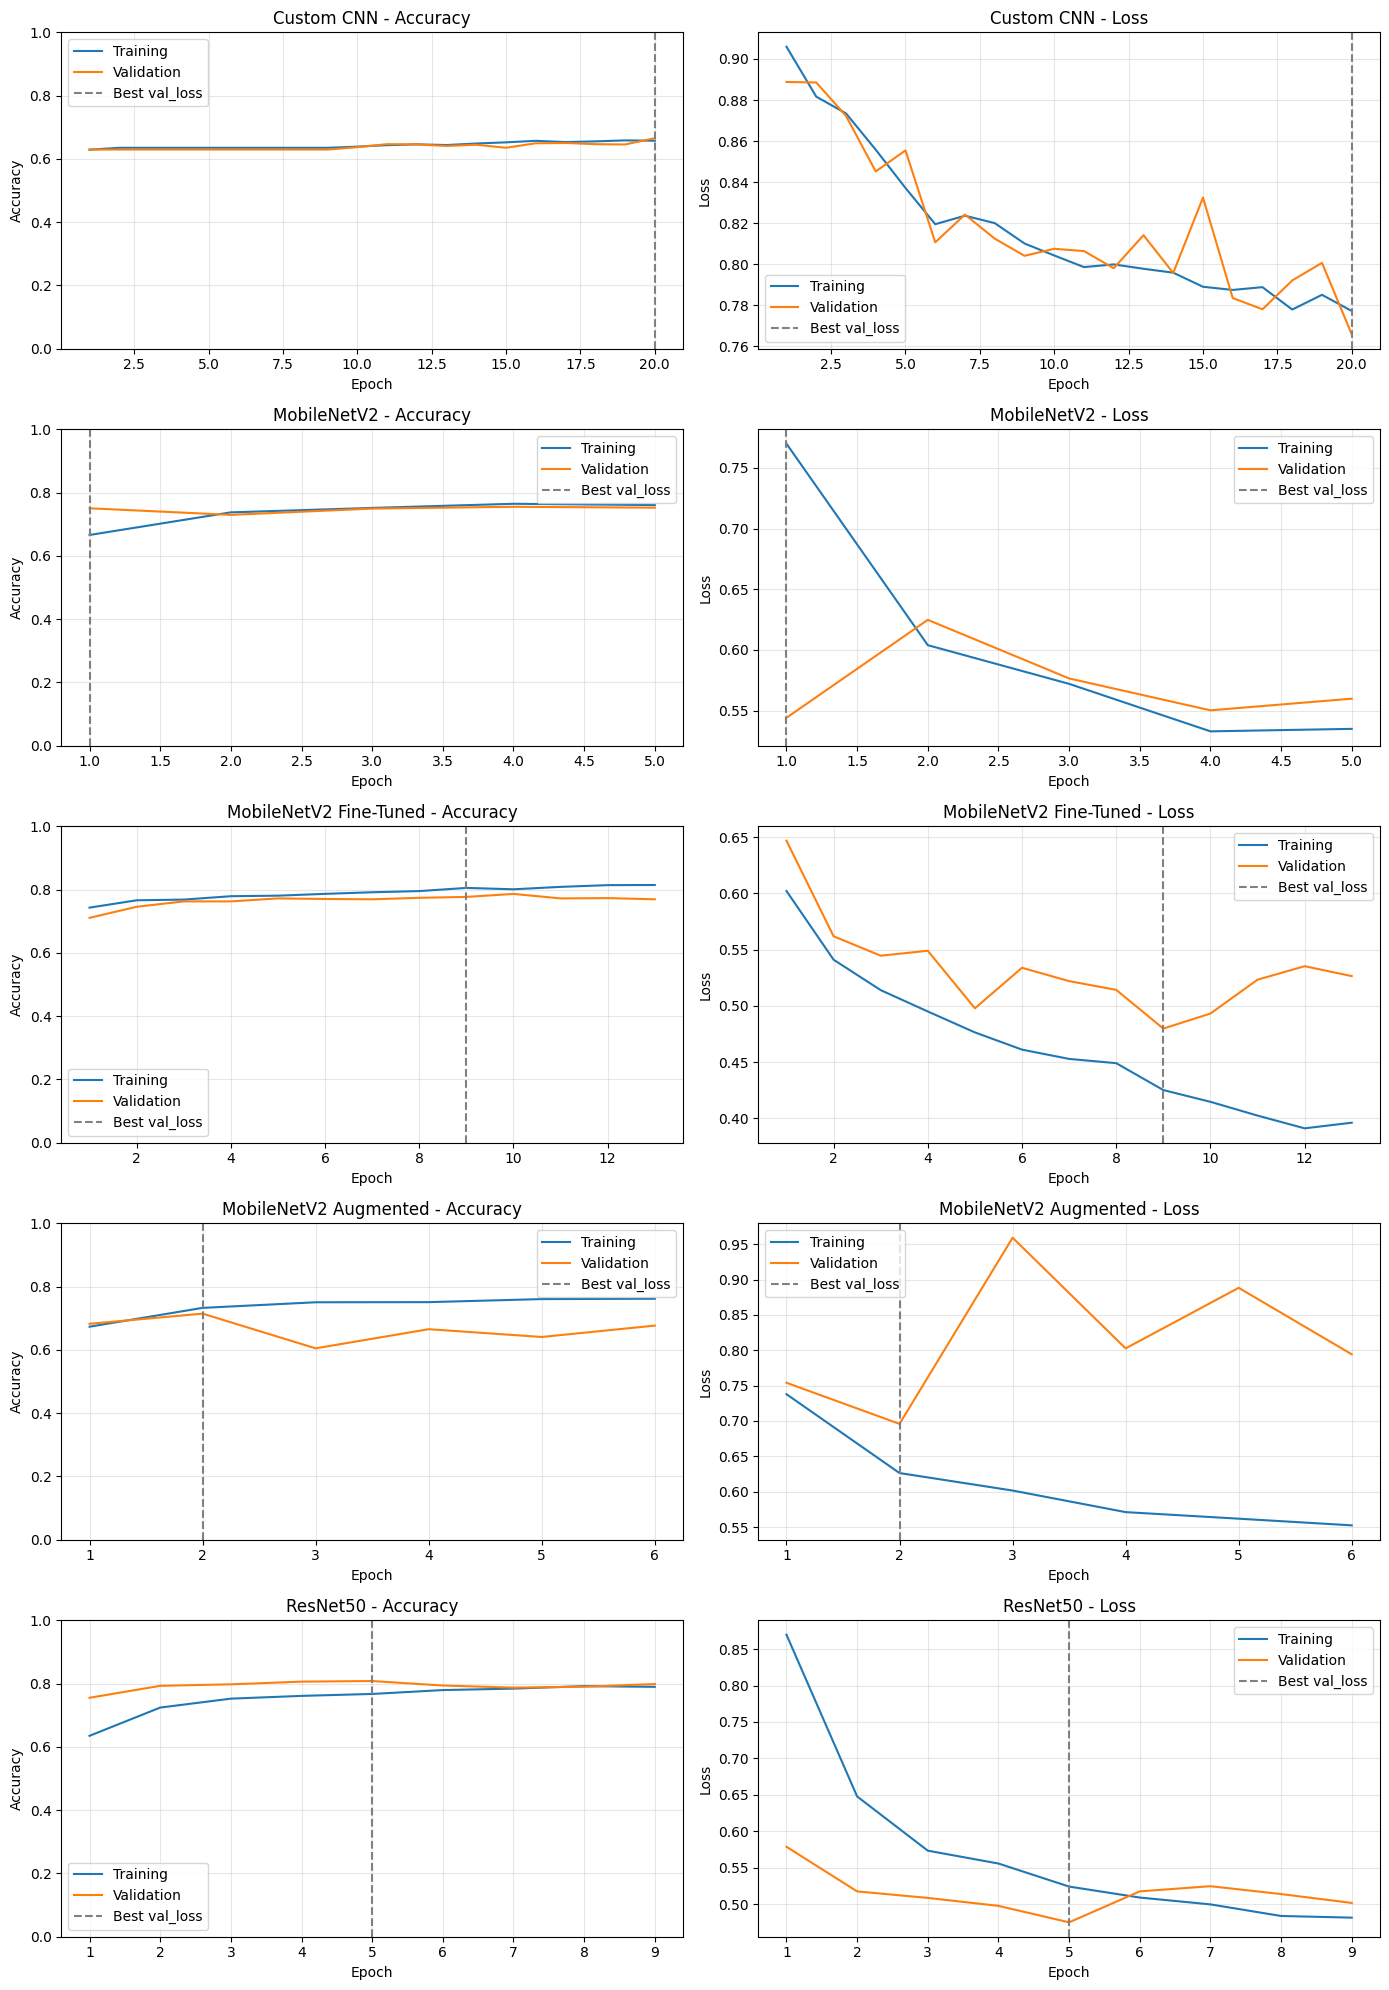

All training histories saved successfully!


In [ ]:

#DEEP LEARNING - TRAINING HISTORY

import matplotlib.pyplot as plt
import pandas as pd

#Collect training histories
histories = {
    "Custom CNN": history_cnn,
    "MobileNetV2": history_mobilenet,
    "MobileNetV2 Fine-Tuned": history_finetune,
    "MobileNetV2 Augmented": history_aug,
    "ResNet50": history_resnet
}

#Create training curves
fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, (model_name, history) in enumerate(histories.items()):

    #Extract training metrics
    metrics = pd.DataFrame(history.history)
    epochs = range(1, len(metrics) + 1)

    best_epoch = metrics["val_loss"].idxmin() + 1

    #Plot accuracy
    axes[i, 0].plot(
        epochs, metrics["accuracy"], label="Training"
    )
    axes[i, 0].plot(
        epochs, metrics["val_accuracy"], label="Validation"
    )

    axes[i, 0].set_title(f"{model_name} - Accuracy")
    axes[i, 0].set_xlabel("Epoch")
    axes[i, 0].set_ylabel("Accuracy")
    axes[i, 0].set_ylim(0, 1)

    #Plot loss
    axes[i, 1].plot(
        epochs, metrics["loss"], label="Training"
    )
    axes[i, 1].plot(
        epochs, metrics["val_loss"], label="Validation"
    )

    axes[i, 1].set_title(f"{model_name} - Loss")
    axes[i, 1].set_xlabel("Epoch")
    axes[i, 1].set_ylabel("Loss")

    #Mark best validation loss epoch
    for ax in axes[i]:
        ax.axvline(
            best_epoch,
            color="gray",
            linestyle="--",
            label="Best val_loss"
        )
        ax.legend()
        ax.grid(alpha=0.3)

    #Save training history
    filename = model_name.lower().replace(" ", "_")

    metrics.insert(0, "Epoch", list(epochs))

    metrics.to_csv(
        RESULTS_DIR / f"{filename}_training_history.csv",
        index=False
    )

#Save training curves
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "deep_learning_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All training histories saved successfully!")
